In [1]:
# IMPORTS
from graph import app 
import pandas as pd
import os
from tqdm.auto import tqdm
import torch
import time 
from Configuration.models import models #import models to evaluate
from dotenv import load_dotenv
from langchain_huggingface import ChatHuggingFace, HuggingFaceEndpoint
from langchain_groq import ChatGroq
from langchain_openai import ChatOpenAI
from langchain_neo4j import Neo4jGraph  # for schema
from langchain_ollama import ChatOllama

In [9]:
import pandas as pd
import numpy as np

# ==========================================
# 1. UPDATE THIS PATH TO YOUR ACTUAL FOLDER
# ==========================================
# files = {
#     '1. Baseline (No Memory)': 'Movies_Experiment/llama3_1_8b/8B_Baseline_evaluated.xlsx',
#     '2. History Only (Errors Feedback)': 'Movies_Experiment/llama3_1_8b/8B_History_Only_evaluated.xlsx',
#     '3. History + Trajectory (Errors & Episodic)': 'Movies_Experiment/llama3_1_8b/8B_History_Trajectory_evaluated.xlsx',
#     '4. Trajectory Only (Episodic Only)': 'Movies_Experiment/llama3_1_8b/8B_Trajectory_Only_evaluated.xlsx',
#     '5. CyVerACT All-In (Full Memory)': 'Movies_Experiment/llama3_1_8b/8B_All_In_evaluated.xlsx'
# }

files = {
    '1. Baseline (No Memory)': 'Movies_Experiment/llama3_2_3b/8B_Baseline_evaluated.xlsx',
    '2. History Only (Errors Feedback)': 'Movies_Experiment/llama3_2_3b/8B_History_Only_evaluated.xlsx',
    '3. History + Trajectory (Errors & Episodic)': 'Movies_Experiment/llama3_2_3b/8B_History_Trajectory_evaluated.xlsx',
    '4. Trajectory Only (Episodic Only)': 'Movies_Experiment/llama3_2_3b/8B_Trajectory_Only_evaluated.xlsx',
    '5. CyVerACT All-In (Full Memory)': 'Movies_Experiment/llama3_2_3b/8B_All_In_evaluated.xlsx'
}

metrics_mapping = {
    'is_KG_Valid_correct': 'Cypher Validity (%)',
    'Pass@1 Output': 'Pass@1 Output (%)',
    'Jaccard Output': 'Positive Jaccard (%)',
    'Jaro Similarity': 'Jaro Similarity',
    'Rouge-L F1-score': 'Rouge-L F1',
    'iterations_calc': 'Mean Iterations' 
}

table_rows = []

for case_name, file_path in files.items():
    try:
        df = pd.read_excel(file_path)
        
        # Clean boolean columns
        for col in ['is_KG_Valid_correct', 'Pass@1 Output', 'Jaccard Output']:
            if col in df.columns:
                df[col] = df[col].fillna(False).astype(bool)
        
        # Calculate Iterations: Count occurrences of 'cypher_corrector' in path + 1 initial attempt
        if 'path' in df.columns:
            df['iterations_calc'] = df['path'].apply(
                lambda x: str(x).count('cypher_corrector') + 1 if not pd.isna(x) else 1
            )
        else:
            df['iterations_calc'] = 1
            
        row_data = {'Configuration': case_name}
        
        # Extract and format metrics
        for col, clean_name in metrics_mapping.items():
            if col == 'iterations_calc':
                val = df['iterations_calc'].mean()
                row_data[clean_name] = round(val, 2)
            elif col in df.columns:
                if col in ['is_KG_Valid_correct', 'Pass@1 Output', 'Jaccard Output']:
                    val = df[col].mean() * 100
                elif col in ['Jaro Similarity', 'Rouge-L F1-score']:
                    val = df[col].mean() * 100 if df[col].mean() <= 1.0 else df[col].mean()
                else:
                    val = df[col].mean()
                row_data[clean_name] = round(val, 2)
            else:
                row_data[clean_name] = "N/A"
                
        table_rows.append(row_data)
        
    except Exception as e:
        print(f"⚠️ Could not load {case_name}. Error: {e}")

# ==========================================
# 2. GENERATE TABLE
# ==========================================
if table_rows:
    summary_table = pd.DataFrame(table_rows)
    print("\n" + "="*80)
    print(" 📊 ABLATION STUDY FINAL METRICS SUMMARY TABLE")
    print("="*80)
    display(summary_table)
    summary_table.to_excel("Final_Ablation_Metrics_Table.xlsx", index=False)
    print("\n✅ Table successfully saved to your folder as 'Final_Ablation_Metrics_Table.xlsx'")


 📊 ABLATION STUDY FINAL METRICS SUMMARY TABLE


,Configuration,Cypher Validity (%),Pass@1 Output (%),Positive Jaccard (%),Jaro Similarity,Rouge-L F1,Mean Iterations
0,1. Baseline (No Memory),62.0,8.0,28.0,82.13,60.42,6.16
1,2. History Only (Errors Feedback),54.0,10.0,24.0,82.82,62.12,6.84
2,3. History + Trajectory (Errors & Episodic),54.0,10.0,26.0,82.53,60.26,6.60
3,4. Trajectory Only (Episodic Only),82.0,16.0,34.0,82.45,61.56,4.38
4,5. CyVerACT All-In (Full Memory),70.0,10.0,30.0,82.70,59.32,4.92



✅ Table successfully saved to your folder as 'Final_Ablation_Metrics_Table.xlsx'


In [13]:
import pandas as pd
import numpy as np

# ==========================================
# 1. LOAD YOUR FINAL EVALUATED PATHS
# ==========================================
# files = {
#     '1. Baseline (No Memory)': 'Movies_Experiment/llama3_1_8b/8B_Baseline_evaluated.xlsx',
#     '2. History Only (Errors Feedback)': 'Movies_Experiment/llama3_1_8b/8B_History_Only_evaluated.xlsx',
#     '3. History + Trajectory (Errors & Episodic)': 'Movies_Experiment/llama3_1_8b/8B_History_Trajectory_evaluated.xlsx',
#     '4. Trajectory Only (Episodic Only)': 'Movies_Experiment/llama3_1_8b/8B_Trajectory_Only_evaluated.xlsx',
#     '5. CyVerACT All-In (Full Memory)': 'Movies_Experiment/llama3_1_8b/8B_All_In_evaluated.xlsx'
# }

files = {
    '1. Baseline (No Memory)': 'Movies_Experiment/llama3_2_3b/8B_Baseline_evaluated.xlsx',
    '2. History Only (Errors Feedback)': 'Movies_Experiment/llama3_2_3b/8B_History_Only_evaluated.xlsx',
    '3. History + Trajectory (Errors & Episodic)': 'Movies_Experiment/llama3_2_3b/8B_History_Trajectory_evaluated.xlsx',
    '4. Trajectory Only (Episodic Only)': 'Movies_Experiment/llama3_2_3b/8B_Trajectory_Only_evaluated.xlsx',
    '5. CyVerACT All-In (Full Memory)': 'Movies_Experiment/llama3_2_3b/8B_All_In_evaluated.xlsx'
}

# The specific columns we want to extract
metrics_mapping = {
    'is_KG_Valid_correct': 'Cypher Validity (%)',
    'Pass@1 Output': 'Pass@1 Output (%)',
    'Jaccard Output': 'Positive Jaccard (%)',
    'Jaro Similarity': 'Jaro Similarity',
    'Rouge-L F1-score': 'Rouge-L F1',
    'total_iterations': 'Mean Iterations'
}

table_rows = []

for case_name, file_path in files.items():
    try:
        df = pd.read_excel(file_path)
        
        # Safely convert boolean columns so pandas can calculate accurate means
        for col in ['is_KG_Valid_correct', 'Pass@1 Output', 'Jaccard Output']:
            if col in df.columns:
                df[col] = df[col].fillna(False).astype(bool)
        
        row_data = {'Configuration': case_name}
        
        # Calculate metric means
        for col, clean_name in metrics_mapping.items():
            if col in df.columns:
                # Multiply 0-1 metrics by 100 to get clean percentages
                if col in ['is_KG_Valid_correct', 'Pass@1 Output', 'Jaccard Output']:
                    val = df[col].mean() * 100
                elif col in ['Jaro Similarity', 'Rouge-L F1-score']:
                    val = df[col].mean() * 100 if df[col].mean() <= 1.0 else df[col].mean()
                else:
                    val = df[col].mean()
                    
                row_data[clean_name] = round(val, 2)
            else:
                row_data[clean_name] = "N/A"
                
        table_rows.append(row_data)
        
    except Exception as e:
        print(f"⚠️ Could not load {case_name}. Error: {e}")

# ==========================================
# 2. GENERATE AND DISPLAY THE TABLE
# ==========================================
if table_rows:
    summary_table = pd.DataFrame(table_rows)
    
    print("\n" + "="*95)
    print(" 📊 ABLATION STUDY FINAL METRICS SUMMARY TABLE")
    print("="*95)
    
    # Display the clean table in the notebook
    display(summary_table)
    
    # Save the final table directly to an Excel file
    summary_table.to_excel("Final_Ablation_Metrics_Table.xlsx", index=False)
    print("\n✅ Table successfully saved to your folder as 'Final_Ablation_Metrics_Table.xlsx'")


 📊 ABLATION STUDY FINAL METRICS SUMMARY TABLE


,Configuration,Cypher Validity (%),Pass@1 Output (%),Positive Jaccard (%),Jaro Similarity,Rouge-L F1,Mean Iterations
0,1. Baseline (No Memory),62.0,8.0,28.0,82.13,60.42,6.70
1,2. History Only (Errors Feedback),54.0,10.0,24.0,82.82,62.12,7.46
2,3. History + Trajectory (Errors & Episodic),54.0,10.0,26.0,82.53,60.26,7.18
3,4. Trajectory Only (Episodic Only),82.0,16.0,34.0,82.45,61.56,4.72
4,5. CyVerACT All-In (Full Memory),70.0,10.0,30.0,82.70,59.32,5.32



✅ Table successfully saved to your folder as 'Final_Ablation_Metrics_Table.xlsx'



 📊 ABLATION STUDY METRIC SUMMARY TABLE


,Configuration,Cypher Validity (%),Mean Corrections
0,1. Baseline (No Memory Context),84.0,2.60
1,2. History Only (Errors Feedback),88.0,2.12
2,3. History + Trajectory (Errors & Episodic),86.0,2.28
3,4. Trajectory Only (Episodic Only),80.0,2.74
4,5. CyVerACT All-In (Full Memory Framework),88.0,2.08


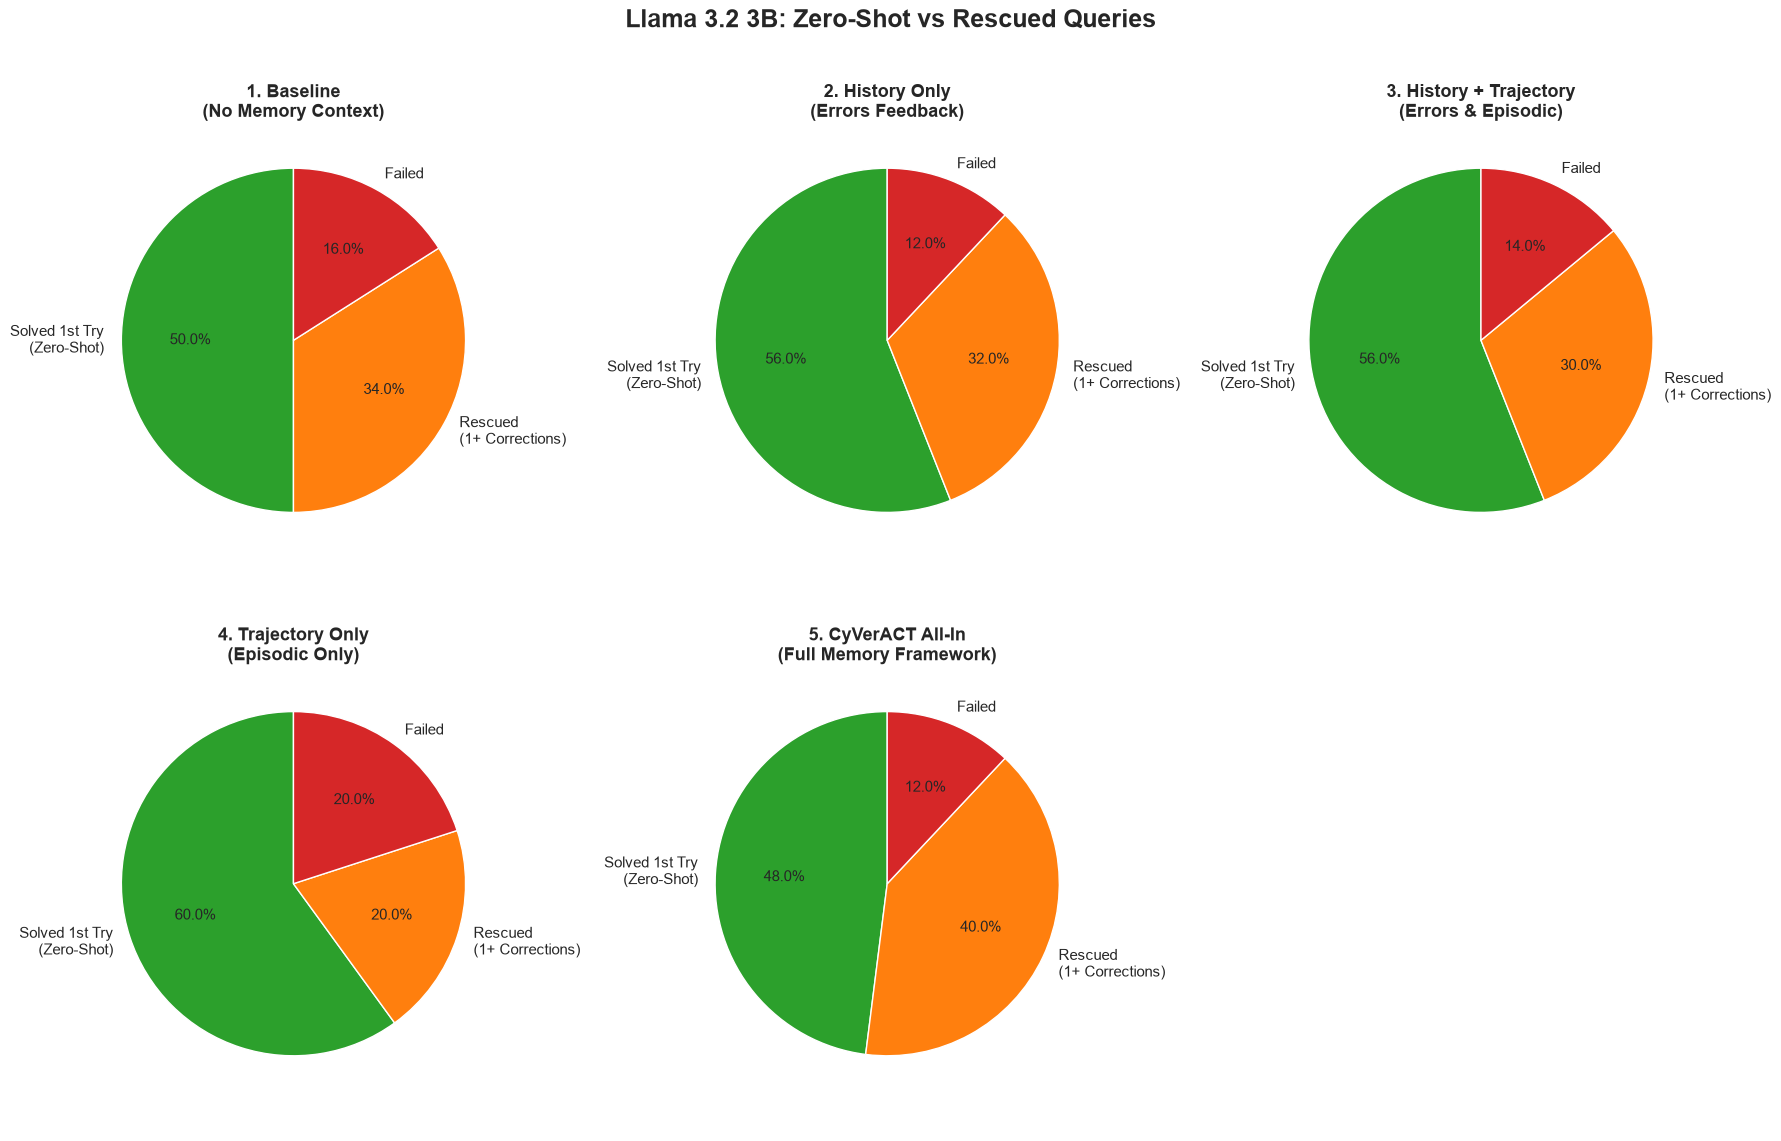

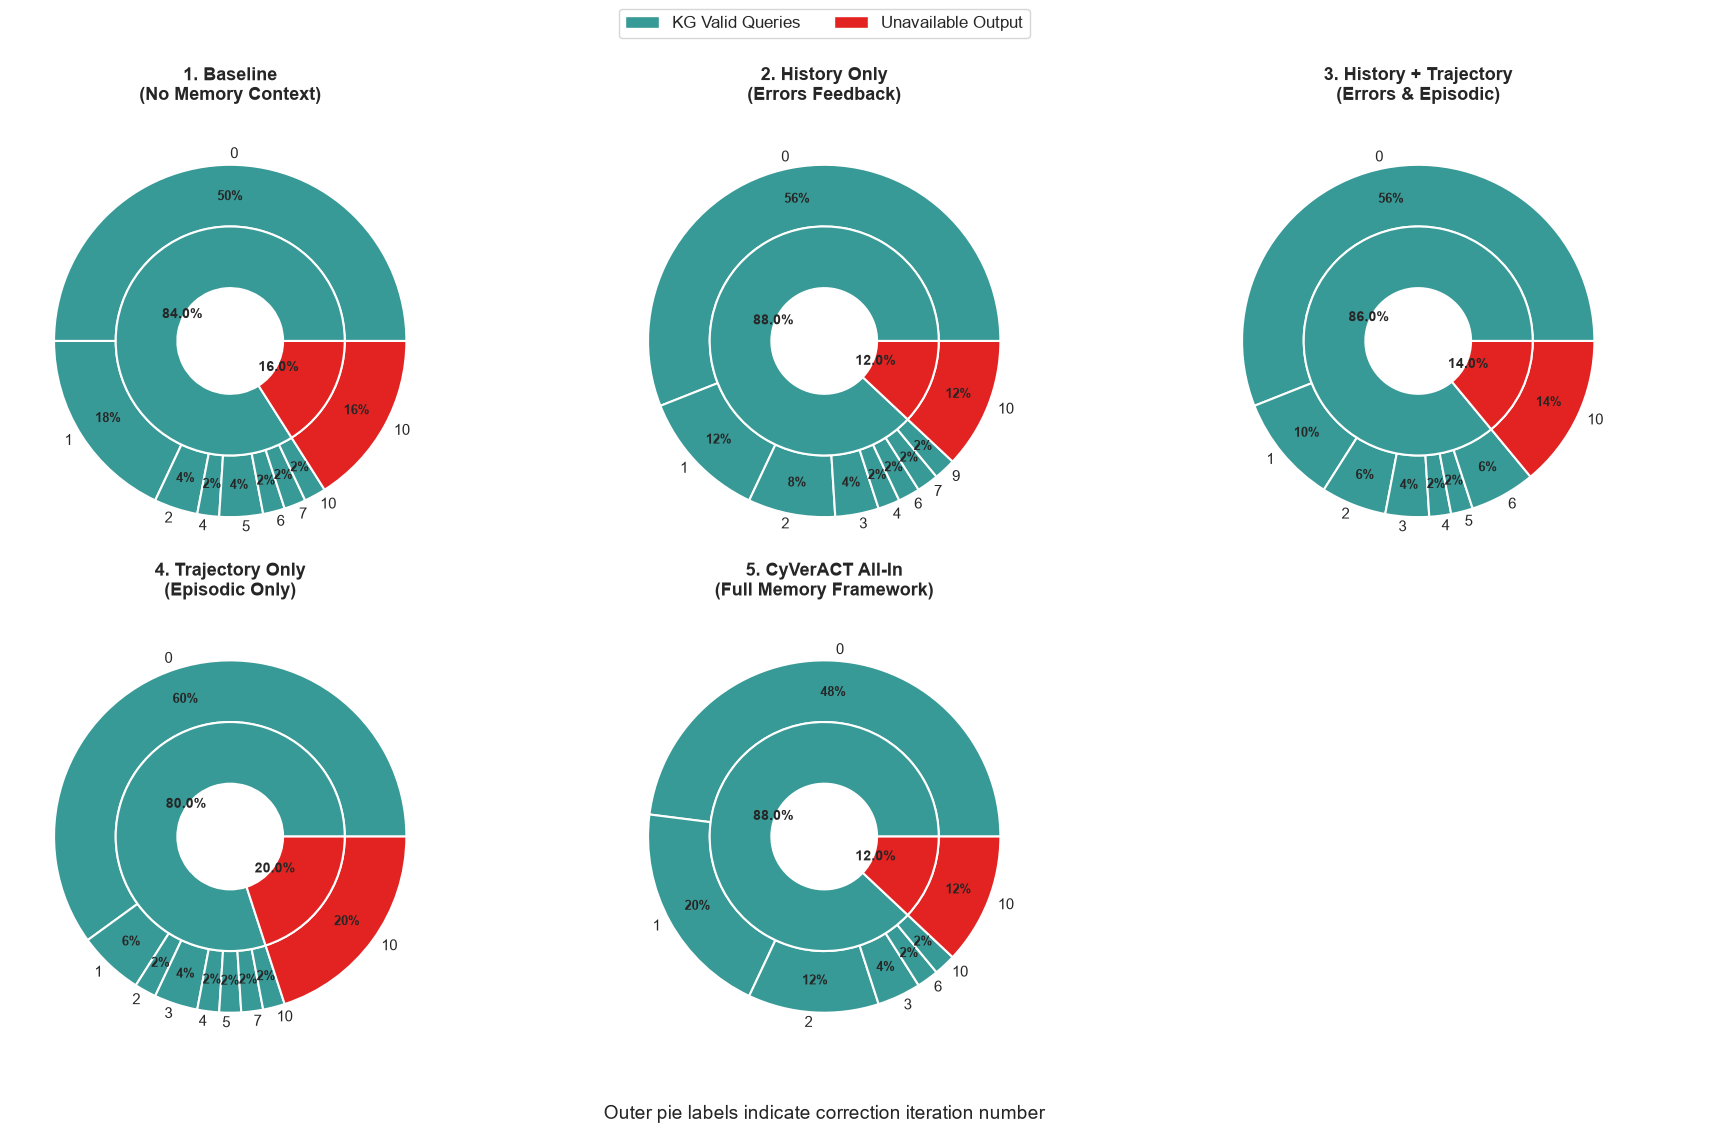

<Figure size 1200x700 with 0 Axes>

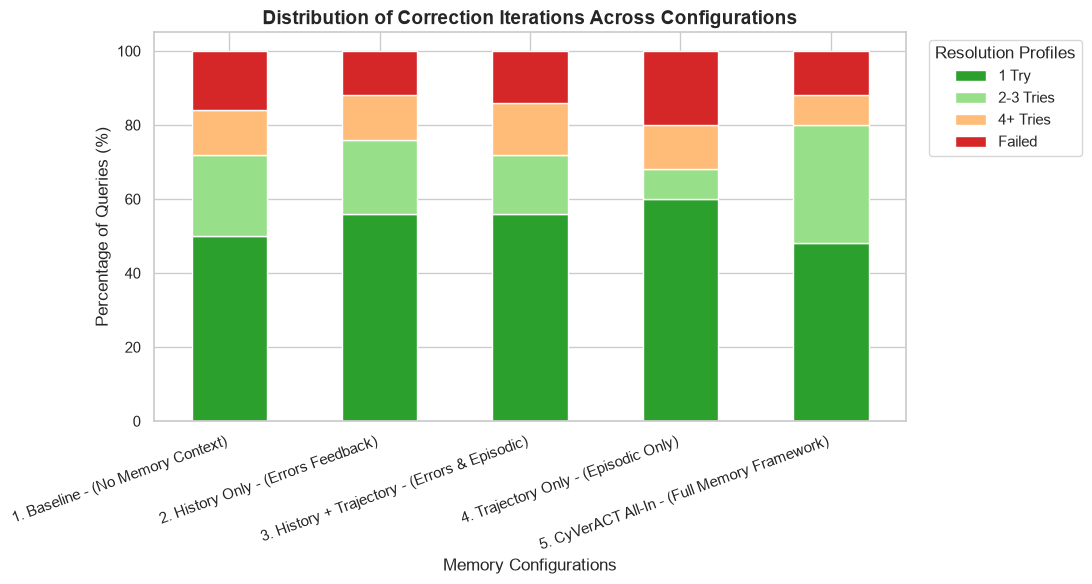

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.patches import Patch

# ==========================================
# 1. LOAD YOUR REVISED DATA PATHS
# ==========================================

files = {
    '8B_Baseline': 'Outputs_Evaluation/Movies_Experiment/BASELINE/50testllama3_1_8b_memory_OFF_baseline/50_test_queries_thesis_50testllama3_1_8b_memory_OFF_baseline.xlsx',
    '8B_History_Only': 'Outputs_Evaluation/Movies_Experiment/HISTORY_ONLY/3llama3_1_8b_memory_OFF/50_test_queries_thesis_3llama3_1_8b_memory_OFF.xlsx', 
    '8B_History_Trajectory': 'Outputs_Evaluation/Movies_Experiment/HISTORY_TRAJECTORY/2llama3_1_8b_memory_OFF/50_test_queries_thesis_2llama3_1_8b_memory_OFF.xlsx',
    '8B_Trajectory_Only': 'Outputs_Evaluation/Movies_Experiment/TRAJECTORY_ONLY/4llama3_1_8b_memory_OFF/50_test_queries_thesis_4llama3_1_8b_memory_OFF.xlsx',
    '8B_All_In': 'Outputs_Evaluation/Movies_Experiment/MEMORY_ALL_IN/llama3_1_8b_memory_OFF/50_test_queries_thesis_llama3_1_8b_memory_OFF.xlsx'  
}

# files = {
#     '3B_Baseline': 'Outputs_Evaluation/Movies_Experiment/BASELINE/50testllama3_2_3b_memory_OFF_baseline/50_test_queries_thesis_50testllama3_2_3b_memory_OFF_baseline.xlsx',
#     '3B_History_Only': 'Outputs_Evaluation/Movies_Experiment/HISTORY_ONLY/3llama3_2_3b_memory_OFF/50_test_queries_thesis_3llama3_2_3b_memory_OFF.xlsx', 
#     '3B_History_Trajectory': 'Outputs_Evaluation/Movies_Experiment/HISTORY_TRAJECTORY/2llama3_2_3b_memory_OFF/50_test_queries_thesis_2llama3_2_3b_memory_OFF.xlsx',
#     '3B_Trajectory_Only': 'Outputs_Evaluation/Movies_Experiment/TRAJECTORY_ONLY/4llama3_2_3b_memory_OFF/50_test_queries_thesis_4llama3_2_3b_memory_OFF.xlsx',
#     '3B_All_In': 'Outputs_Evaluation/Movies_Experiment/MEMORY_ALL_IN/llama3_2_3b_memory_OFF/50_test_queries_thesis_llama3_2_3b_memory_OFF.xlsx'  
# }

# Display titles for the charts so they look clean and academic
display_names = {
    '8B_Baseline': '1. Baseline\n(No Memory Context)',
    '8B_History_Only': '2. History Only\n(Errors Feedback)',
    '8B_History_Trajectory': '3. History + Trajectory\n(Errors & Episodic)',
    '8B_Trajectory_Only': '4. Trajectory Only\n(Episodic Only)',
    '8B_All_In': '5. CyVerACT All-In\n(Full Memory Framework)'
}

dfs = {}
for name, path in files.items():
    try:
        df = pd.read_excel(path)
        # Ensure booleans are cleanly cast for pandas calculations
        df['is_KG_Valid_correct'] = df['is_KG_Valid_correct'].fillna(False).astype(bool)
        
        # Calculate corrections based on 'cypher_corrector' occurrences in the 'path' column
        df['corrections'] = df['path'].apply(lambda x: str(x).count('cypher_corrector') if not pd.isna(x) else 0)
        
        dfs[name] = df
    except Exception as e:
        print(f"Error loading file: {name}. Missing path or corrupted data. Details: {e}")

# Proceed only if all requested experiment datasets are successfully loaded
if len(dfs) == len(files):
    sns.set_theme(style="whitegrid")

    # ==========================================
    # 2. GENERATE METRICS SUMMARY TABLE
    # ==========================================
    table_rows = []
    for config_name, df in dfs.items():
        row_data = {
            'Configuration': display_names[config_name].replace('\n', ' '),
            'Cypher Validity (%)': round(df['is_KG_Valid_correct'].mean() * 100, 2),
            'Mean Corrections': round(df['corrections'].mean(), 2)
        }
        table_rows.append(row_data)

    summary_table = pd.DataFrame(table_rows)
    print("\n" + "="*60)
    print(" 📊 ABLATION STUDY METRIC SUMMARY TABLE")
    print("="*60)
    display(summary_table) 
    summary_table.to_excel("Ablation_Study_Summary_Table.xlsx", index=False)


    # ==========================================
    # PLOT 1: Zero-Shot Success Pie Charts 
    # ==========================================
    fig1, axes1 = plt.subplots(nrows=2, ncols=3, figsize=(18, 12))
    axes1 = axes1.flatten()
    axes1[5].axis('off') 

    def get_rescue_pie_data(df):
        correct = df[df['is_KG_Valid_correct'] == True]
        first_try = len(correct[correct['corrections'] == 0])
        rescued = len(correct[correct['corrections'] > 0])
        failed = len(df[df['is_KG_Valid_correct'] == False])
        return [first_try, rescued, failed]
        
    labels_rescue = ['Solved 1st Try\n(Zero-Shot)', 'Rescued\n(1+ Corrections)', 'Failed']
    colors_rescue = ['#2ca02c', '#ff7f0e', '#d62728'] 

    for idx, (config_name, df) in enumerate(dfs.items()):
        ax = axes1[idx]
        data = get_rescue_pie_data(df)
        ax.pie(data, labels=labels_rescue, colors=colors_rescue, autopct='%1.1f%%', startangle=90, textprops={'fontsize': 11})
        ax.set_title(display_names[config_name], fontsize=13, fontweight='bold')

    plt.suptitle('Llama 3.2 3B: Zero-Shot vs Rescued Queries', fontsize=18, fontweight='bold', y=0.95)
    plt.tight_layout()
    plt.subplots_adjust(top=0.88)
    plt.savefig('3B_ablation_rescue_pie_charts.png', dpi=300, bbox_inches='tight')
    plt.show()


    # ==============================================================
    # PLOT 2: NESTED DONUT CHART (Valid vs Failed Iterations)
    # ==============================================================
    fig2, axes2 = plt.subplots(nrows=2, ncols=3, figsize=(18, 12))
    axes2 = axes2.flatten()
    axes2[5].axis('off') 

    def get_inner_category(row):
        return 'Valid' if row['is_KG_Valid_correct'] else 'Failed'

    color_valid = '#389A97'   # Teal
    color_failed = '#E32322'  # Red

    legend_elements = [
        Patch(facecolor=color_valid, edgecolor='w', label='KG Valid Queries'),
        Patch(facecolor=color_failed, edgecolor='w', label='Unavailable Output')
    ]
    fig2.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, 0.98), ncol=2, fontsize=12, frameon=True)

    ring_width = 0.35

    for idx, (config_name, df) in enumerate(dfs.items()):
        ax = axes2[idx]
        df_temp = df.copy()
        df_temp['Category'] = df_temp.apply(get_inner_category, axis=1)

        # Build Inner Ring
        inner_sizes = []
        inner_colors = []
        for cat, col in zip(['Valid', 'Failed'], [color_valid, color_failed]):
            count = (df_temp['Category'] == cat).sum()
            if count > 0:
                inner_sizes.append(count)
                inner_colors.append(col)

        # Build Outer Ring (Grouped by number of corrections)
        outer_sizes = []
        outer_colors = []
        outer_labels = []

        # 1. Outer slices for Valid Queries
        sub_valid = df_temp[df_temp['Category'] == 'Valid']
        for loops in sorted(sub_valid['corrections'].unique()):
            count = (sub_valid['corrections'] == loops).sum()
            if count > 0:
                outer_sizes.append(count)
                outer_colors.append(color_valid)
                outer_labels.append(str(int(loops))) # Label = number of correction loops

        # 2. Outer slices for Failed Queries
        sub_failed = df_temp[df_temp['Category'] == 'Failed']
        for loops in sorted(sub_failed['corrections'].unique()):
            count = (sub_failed['corrections'] == loops).sum()
            if count > 0:
                outer_sizes.append(count)
                outer_colors.append(color_failed)
                outer_labels.append(str(int(loops)))

        # Draw Outer Ring (Detailed Corrections)
        # CHANGED: autopct is now '%1.0f%%' so it always shows the percentage
        _, _, outer_autotexts = ax.pie(
            outer_sizes, radius=1, colors=outer_colors,
            wedgeprops=dict(width=ring_width, edgecolor='w', linewidth=1.5),
            labels=outer_labels, labeldistance=1.06,
            autopct='%1.0f%%', pctdistance=0.82
        )
        for t in outer_autotexts:
            t.set_fontsize(9)
            t.set_weight('bold')

        # Draw Inner Ring (Main Breakdown)
        _, _, inner_autotexts = ax.pie(
            inner_sizes, radius=1 - ring_width, colors=inner_colors,
            wedgeprops=dict(width=ring_width, edgecolor='w', linewidth=1.5),
            autopct='%1.1f%%', pctdistance=0.48
        )
        for t in inner_autotexts:
            t.set_fontsize(10)
            t.set_weight('bold')

        ax.set_title(display_names[config_name], fontsize=13, fontweight='bold', pad=15)

    plt.suptitle('Outer pie labels indicate correction iteration number', fontsize=14, y=0.06)
    plt.tight_layout()
    plt.subplots_adjust(top=0.88, bottom=0.1)
    plt.savefig('3B_ablation_iterations_nested_donut.png', dpi=300, bbox_inches='tight')
    plt.show()


    # ==========================================
    # PLOT 3: Ablation Iteration Distribution (Stacked Bar)
    # ==========================================
    def categorize_iterations(row):
        if not row['is_KG_Valid_correct']:
            return 'Failed'
        elif row['corrections'] == 0:
            return '1 Try'       # 0 corrections = solved immediately
        elif row['corrections'] <= 2:
            return '2-3 Tries'   # 1-2 corrections = solved on 2nd or 3rd try
        else:
            return '4+ Tries'    # 3+ corrections

    colors_iter = ['#2ca02c', '#98df8a', '#ffbb78', '#d62728']

    dist_data = []
    for config_name in files.keys():
        df = dfs[config_name].copy()
        df['Bucket'] = df.apply(categorize_iterations, axis=1)
        counts = df['Bucket'].value_counts(normalize=True) * 100
        
        display_name = display_names[config_name].replace('\n', ' - ')
        
        dist_data.append({
            'Configuration': display_name,
            '1 Try': counts.get('1 Try', 0),
            '2-3 Tries': counts.get('2-3 Tries', 0),
            '4+ Tries': counts.get('4+ Tries', 0),
            'Failed': counts.get('Failed', 0)
        })

    dist_df = pd.DataFrame(dist_data).set_index('Configuration')
    
    plt.figure(figsize=(12, 7))
    ax = dist_df[['1 Try', '2-3 Tries', '4+ Tries', 'Failed']].plot(
        kind='bar', stacked=True, figsize=(11, 6), 
        color=colors_iter
    )
    plt.title('Distribution of Correction Iterations Across Configurations', fontsize=14, fontweight='bold')
    plt.ylabel('Percentage of Queries (%)', fontsize=12)
    plt.xlabel('Memory Configurations', fontsize=12)
    plt.xticks(rotation=20, ha='right', fontsize=11)
    plt.legend(title='Resolution Profiles', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=11)
    plt.tight_layout()
    plt.savefig('3B_iteration_distribution_stacked.png', dpi=300, bbox_inches='tight')
    plt.show()

else:
    print("Execution Blocked: Please verify that all 5 required Excel files exist in their specified folders before processing charts.")

In [1]:
import pandas as pd

# 1. Load the original dataset
# (If your file is saved as a CSV, use pd.read_csv('test.csv') instead)
df = pd.read_excel('C:/Users/olgag/Desktop/agentic-memory/CyVerACT/data/text2cypher-2024v1/test.xlsx')

# 2. Filter the dataframe for the 'movies' database
df_movies = df[df['database_name'] == 'movies']

# 3. Export the filtered data to a new Excel file
# index=False prevents pandas from writing the row numbers into the file
df_movies.to_excel('movies_queries.xlsx', index=False)

print(f"Successfully exported {len(df_movies)} queries to movies_queries.xlsx")

Successfully exported 203 queries to movies_queries.xlsx


In [1]:
import pandas as pd

# 1. Load the original dataset
df = pd.read_excel('movies_queries.xlsx')

# 2. Sort by complexity (Cypher length)
df['cypher_length'] = df['cypher'].apply(lambda x: len(str(x)))
df_sorted = df.sort_values(by='cypher_length').reset_index(drop=True)

# 3. Take 100 total queries (stratified)
selected_indices = [int(i * (len(df_sorted) / 100)) for i in range(100)]
df_subset = df_sorted.iloc[selected_indices].copy().reset_index(drop=True)

# 4. 50/50 Alternating Split: Even indices go to Memory, Odd indices go to Test
df_subset['split'] = ['Test' if i % 2 == 1 else 'Memory' for i in range(len(df_subset))]

# 5. Export
df_memory = df_subset[df_subset['split'] == 'Memory'].drop(columns=['cypher_length', 'split'])
df_test = df_subset[df_subset['split'] == 'Test'].drop(columns=['cypher_length', 'split'])

df_memory.to_excel('50_memory_queries_thesis.xlsx', index=False)
df_test.to_excel('50_test_queries_thesis.xlsx', index=False)

print(f"Memory Set: {len(df_memory)} queries exported.")
print(f"Test Set: {len(df_test)} queries exported.")

Memory Set: 50 queries exported.
Test Set: 50 queries exported.


In [12]:
import pandas as pd
import numpy as np
import os
from utils.Evaluation.calculate_metrics import calculate_scores_benchmark_without_original_validation

# Define the exact files provided
# files = {
#     '8B_Baseline': 'Outputs_Evaluation/Movies_Experiment/BASELINE/50testllama3_1_8b_memory_OFF_baseline/50_test_queries_thesis_50testllama3_1_8b_memory_OFF_baseline.xlsx',
#     '8B_History_Only': 'Outputs_Evaluation/Movies_Experiment/HISTORY_ONLY/3llama3_1_8b_memory_OFF/50_test_queries_thesis_3llama3_1_8b_memory_OFF.xlsx', 
#     '8B_History_Trajectory': 'Outputs_Evaluation/Movies_Experiment/HISTORY_TRAJECTORY/2llama3_1_8b_memory_OFF/50_test_queries_thesis_2llama3_1_8b_memory_OFF.xlsx',
#     '8B_Trajectory_Only': 'Outputs_Evaluation/Movies_Experiment/TRAJECTORY_ONLY/4llama3_1_8b_memory_OFF/50_test_queries_thesis_4llama3_1_8b_memory_OFF.xlsx',
#     '8B_All_In': 'Outputs_Evaluation/Movies_Experiment/MEMORY_ALL_IN/llama3_1_8b_memory_OFF/50_test_queries_thesis_llama3_1_8b_memory_OFF.xlsx'  
# }

files = {
    '8B_Baseline': 'Outputs_Evaluation/Movies_Experiment/BASELINE/50testllama3_2_3b_memory_OFF_baseline/50_test_queries_thesis_50testllama3_2_3b_memory_OFF_baseline.xlsx',
    '8B_History_Only': 'Outputs_Evaluation/Movies_Experiment/HISTORY_ONLY/3llama3_2_3b_memory_OFF/50_test_queries_thesis_3llama3_2_3b_memory_OFF.xlsx', 
    '8B_History_Trajectory': 'Outputs_Evaluation/Movies_Experiment/HISTORY_TRAJECTORY/2llama3_2_3b_memory_OFF/50_test_queries_thesis_2llama3_2_3b_memory_OFF.xlsx',
    '8B_Trajectory_Only': 'Outputs_Evaluation/Movies_Experiment/TRAJECTORY_ONLY/4llama3_2_3b_memory_OFF/50_test_queries_thesis_4llama3_2_3b_memory_OFF.xlsx',
    '8B_All_In': 'Outputs_Evaluation/Movies_Experiment/MEMORY_ALL_IN/llama3_2_3b_memory_OFF/50_test_queries_thesis_llama3_2_3b_memory_OFF.xlsx'  
}

# Summary list for final printing
summary_results = []

for config_name, file_path in files.items():
    print(f"\n--- Processing: {config_name} ---")
    if not os.path.exists(file_path):
        print(f"File not found: {file_path}")
        continue
        
    workflow_df = pd.read_excel(file_path).astype(object)
    
    # Run the scoring pipeline
    # We use a unique pkl name to ensure we don't overwrite previous runs
    evaluated_df = calculate_scores_benchmark_without_original_validation(
        model_name='llama3_2_3b',
        model_name_pkl=f"{config_name}_evaluated",
        dataset='Movies_Experiment',
        input_df=workflow_df
    )
    
    # Ensure iterations are correctly captured. 
    # If your Excel already has the 'total_iterations' column, this preserves it.
    if 'total_iterations' not in evaluated_df.columns:
         def extract_iterations(history_value):
             if pd.isna(history_value) or str(history_value).strip() in ["", "None", "[]"]: return 1
             try: return len(eval(str(history_value)))
             except: return 1
         evaluated_df['total_iterations'] = evaluated_df['cypher_errors_history'].apply(extract_iterations)

    # Collect summary stats for this config
    queries_count = len(evaluated_df)
    pass_score = evaluated_df['Pass@1 Output'].fillna(False).sum()
    avg_loops = evaluated_df['total_iterations'].mean()
    
    summary_results.append({
        'Configuration': config_name,
        'Queries': queries_count,
        'Pass@1 (%)': round((pass_score/queries_count)*100, 2),
        'Mean Iterations': round(avg_loops, 2)
    })

# Print final comparative table
print("\n" + "="*60)
print("📊 FINAL BENCHMARK COMPARISON TABLE")
print("="*60)
print(pd.DataFrame(summary_results))
print("="*60)


--- Processing: 8B_Baseline ---
Full path to the directory: c:\Users\olgag\Desktop\agentic-memory\CyVerACT\extended_workflow\Movies_Experiment\llama3_2_3b
Reading the file we give


  0%|          | 0/50 [00:00<?, ?it/s]

0 movies
Original Query: MATCH (p:Person) WHERE p.born < 1960 RETURN p.name
Generated Query: MATCH (p:Person {born: {lessThan: 1960}})-[:ACTED_IN]->(m:Movie) RETURN m.title, p.name
Syntax Valid: True
Schema Valid: 1.0
Properties Valid: 1.0
Is KG Valid: True
BLEU: 0.153875690627633
Rouge-L Precision: 0.53
Rouge-L Recall: 0.8
Rouge-L F1-score: 0.64
Jaro Similarity: 0.6788400437990271
Jaccard Similarity: 0.5384615384615384
Calculating pass and jaccard output metrics...
Pass@1 Output: False
Jaccard Output: 0.0
1 movies
Original Query: MATCH (m:Movie) WHERE m.title CONTAINS "Mail" RETURN m.title
Generated Query: MATCH (p:Person)-[:ACTED_IN|DIRECTED|PRODUCED|WROTE|REVIEWED]->(m:Movie)
WHERE m.tagline CONTAINS "Mail"
RETURN m.title
Syntax Valid: True
Schema Valid: 1.0
Properties Valid: 1.0
Is KG Valid: True
BLEU: 0.4386913376508308
Rouge-L Precision: 0.53
Rouge-L Recall: 0.91
Rouge-L F1-score: 0.67
Jaro Similarity: 0.6351175940776704
Jaccard Similarity: 0.6666666666666666
Calculating pass and

2 movies
Original Query: MATCH (m:Movie) WHERE m.tagline CONTAINS 'journey' RETURN m LIMIT 3
Generated Query: MATCH (m:Movie)-[:REVIEWED]->(r:Review)
WHERE r.summary CONTAINS 'journey'
RETURN m.title LIMIT 3


Syntax Valid: True
Schema Valid: 0.5
Properties Valid: 0.5
Is KG Valid: False
BLEU: 0.2837655732884959
Rouge-L Precision: 0.62
Rouge-L Recall: 0.83
Rouge-L F1-score: 0.71
Jaro Similarity: 0.8471370479143989
Jaccard Similarity: 0.6
KG valid check False
answer check I couldn't find any relevant information in the database
3 movies
Original Query: MATCH (m:Movie {tagline: 'Welcome to the Real World'}) RETURN m.title
Generated Query: MATCH (m:Movie {tagline: 'Welcome to the Real World'})
RETURN m
Syntax Valid: True
Schema Valid: 1.0
Properties Valid: 1.0
Is KG Valid: True
BLEU: 0.8890097654027757
Rouge-L Precision: 1.0
Rouge-L Recall: 0.92
Rouge-L F1-score: 0.96
Jaro Similarity: 0.9794871794871794
Jaccard Similarity: 0.9090909090909091
Calculating pass and jaccard output metrics...
Pass@1 Output: False
Jaccard Output: 0.25
4 movies
Original Query: MATCH (p:Person)-[:ACTED_IN]->(m:Movie {title: "Titanic"}) RETURN p.name
Generated Query: MATCH (m:Movie {title: "Titanic"})<-[:ACTED_IN]-(a:Per

...

Syntax Valid: True
Schema Valid: 0.5
Properties Valid: 1.0
Is KG Valid: False
BLEU: 0.579825193285928
Rouge-L Precision: 0.93
Rouge-L Recall: 0.76
Rouge-L F1-score: 0.84
Jaro Similarity: 0.8995989782886334
Jaccard Similarity: 0.7333333333333333
KG valid check False
answer check I couldn't find any relevant information in the database
17 movies
Original Query: MATCH (m:Movie)<-[r:REVIEWED]-() WHERE size(m.tagline) > 20 RETURN avg(r.rating) AS average_rating
Generated Query: MATCH (m:Movie {tagline: {length: size(m.tagline) > 20}}) OPTIONAL MATCH (m)-[r:REVIEWED]-() RETURN avg(r.rating)
Syntax Valid: True
Schema Valid: 1.0
Properties Valid: 1.0
Is KG Valid: True
BLEU: 0.5236600055265322
Rouge-L Precision: 0.61
Rouge-L Recall: 0.65
Rouge-L F1-score: 0.63
Jaro Similarity: 0.8414588292456784
Jaccard Similarity: 0.6875
Calculating pass and jaccard output metrics...
Pass@1 Output: False
Jaccard Output: 0.0
18 movies
Original Query: MATCH (p:Person)-[r:REVIEWED]->(m:Movie) WHERE p.born > 1980 

19 movies
Original Query: MATCH (m:Movie) WHERE m.tagline IS NOT NULL RETURN m.title, m.tagline ORDER BY m.tagline DESC LIMIT 3
Generated Query: MATCH (m:Movie)-[:REVIEWED]->(r:Review)
RETURN m, COUNT(DISTINCT r.tagline) as count, m.title
ORDER BY count DESC
LIMIT 3


Syntax Valid: True
Schema Valid: 0.5
Properties Valid: 0.5
Is KG Valid: False
BLEU: 0.2264075759239749
Rouge-L Precision: 0.55
Rouge-L Recall: 0.57
Rouge-L F1-score: 0.56
Jaro Similarity: 0.8279181790683605
Jaccard Similarity: 0.5238095238095238
KG valid check False
answer check I couldn't find any relevant information in the database
20 movies
Original Query: MATCH (:Person)-[review:REVIEWED]->(:Movie) WITH max(review.rating) AS highestRating RETURN highestRating
Generated Query: MATCH (p:Person)-[:REVIEWED]->(m:Movie)
RETURN max(m.released)
Syntax Valid: True
Schema Valid: 1.0
Properties Valid: 1.0
Is KG Valid: True
BLEU: 0.35555782812108616
Rouge-L Precision: 0.5
Rouge-L Recall: 0.38
Rouge-L F1-score: 0.43
Jaro Similarity: 0.8340763485137994
Jaccard Similarity: 0.42857142857142855
Calculating pass and jaccard output metrics...
Pass@1 Output: False
Jaccard Output: 0.0
21 movies
Original Query: MATCH (m:Movie {released: 2003})<-[r:REVIEWED]-() WITH avg(r.rating) AS averageRating RETUR

Syntax Valid: False
Schema Valid: 0.7222222222222222
Properties Valid: 0.3333333333333333
Is KG Valid: False
BLEU: 0.39825910804855275
Rouge-L Precision: 0.46
Rouge-L Recall: 0.59
Rouge-L F1-score: 0.52
Jaro Similarity: 0.8663130365006166
Jaccard Similarity: 0.45454545454545453
KG valid check False
answer check I couldn't find any relevant information in the database
24 movies
Original Query: MATCH (p:Person)-[:ACTED_IN]->(m:Movie) WHERE p.born < 1950 AND m.tagline CONTAINS 'limits' RETURN p.name LIMIT 3
Generated Query: MATCH (p:Person {born: {lessThan: 1950}})-[:ACTED_IN]->(m:Movie {tagline: 'limits'}) RETURN p.name LIMIT 3
Syntax Valid: True
Schema Valid: 1.0
Properties Valid: 1.0
Is KG Valid: True
BLEU: 0.5093688452099325
Rouge-L Precision: 0.82
Rouge-L Recall: 0.67
Rouge-L F1-score: 0.74
Jaro Similarity: 0.8727010878621249
Jaccard Similarity: 0.7777777777777778
Calculating pass and jaccard output metrics...
Pass@1 Output: False
Jaccard Output: 0.0
25 movies
Original Query: MATCH (

Syntax Valid: False
Schema Valid: 0.7777777777777778
Properties Valid: 0.5
Is KG Valid: False
BLEU: 0.09976412478949673
Rouge-L Precision: 0.23
Rouge-L Recall: 0.33
Rouge-L F1-score: 0.27
Jaro Similarity: 0.6174588396277366
Jaccard Similarity: 0.1875
KG valid check False
answer check I couldn't find any relevant information in the database
40 movies
Original Query: MATCH (m:Movie)<-[:ACTED_IN]-(p:Person) WITH m, count(DISTINCT p) AS actorCount ORDER BY actorCount DESC LIMIT 3 RETURN m.title AS movieTitle, actorCount
Generated Query: MATCH (p:Person)-[:ACTED_IN]->(m:Movie)
WITH m, COLLECT(DISTINCT p) as actors
ORDER BY SIZE(actors) DESC
RETURN m.title, SIZE(actors)
Syntax Valid: True
Schema Valid: 1.0
Properties Valid: 1.0
Is KG Valid: True
BLEU: 0.40073769959966155
Rouge-L Precision: 0.58
Rouge-L Recall: 0.54
Rouge-L F1-score: 0.56
Jaro Similarity: 0.8656756383712906
Jaccard Similarity: 0.6363636363636364
Calculating pass and jaccard output metrics...
Pass@1 Output: False
Jaccard Outpu

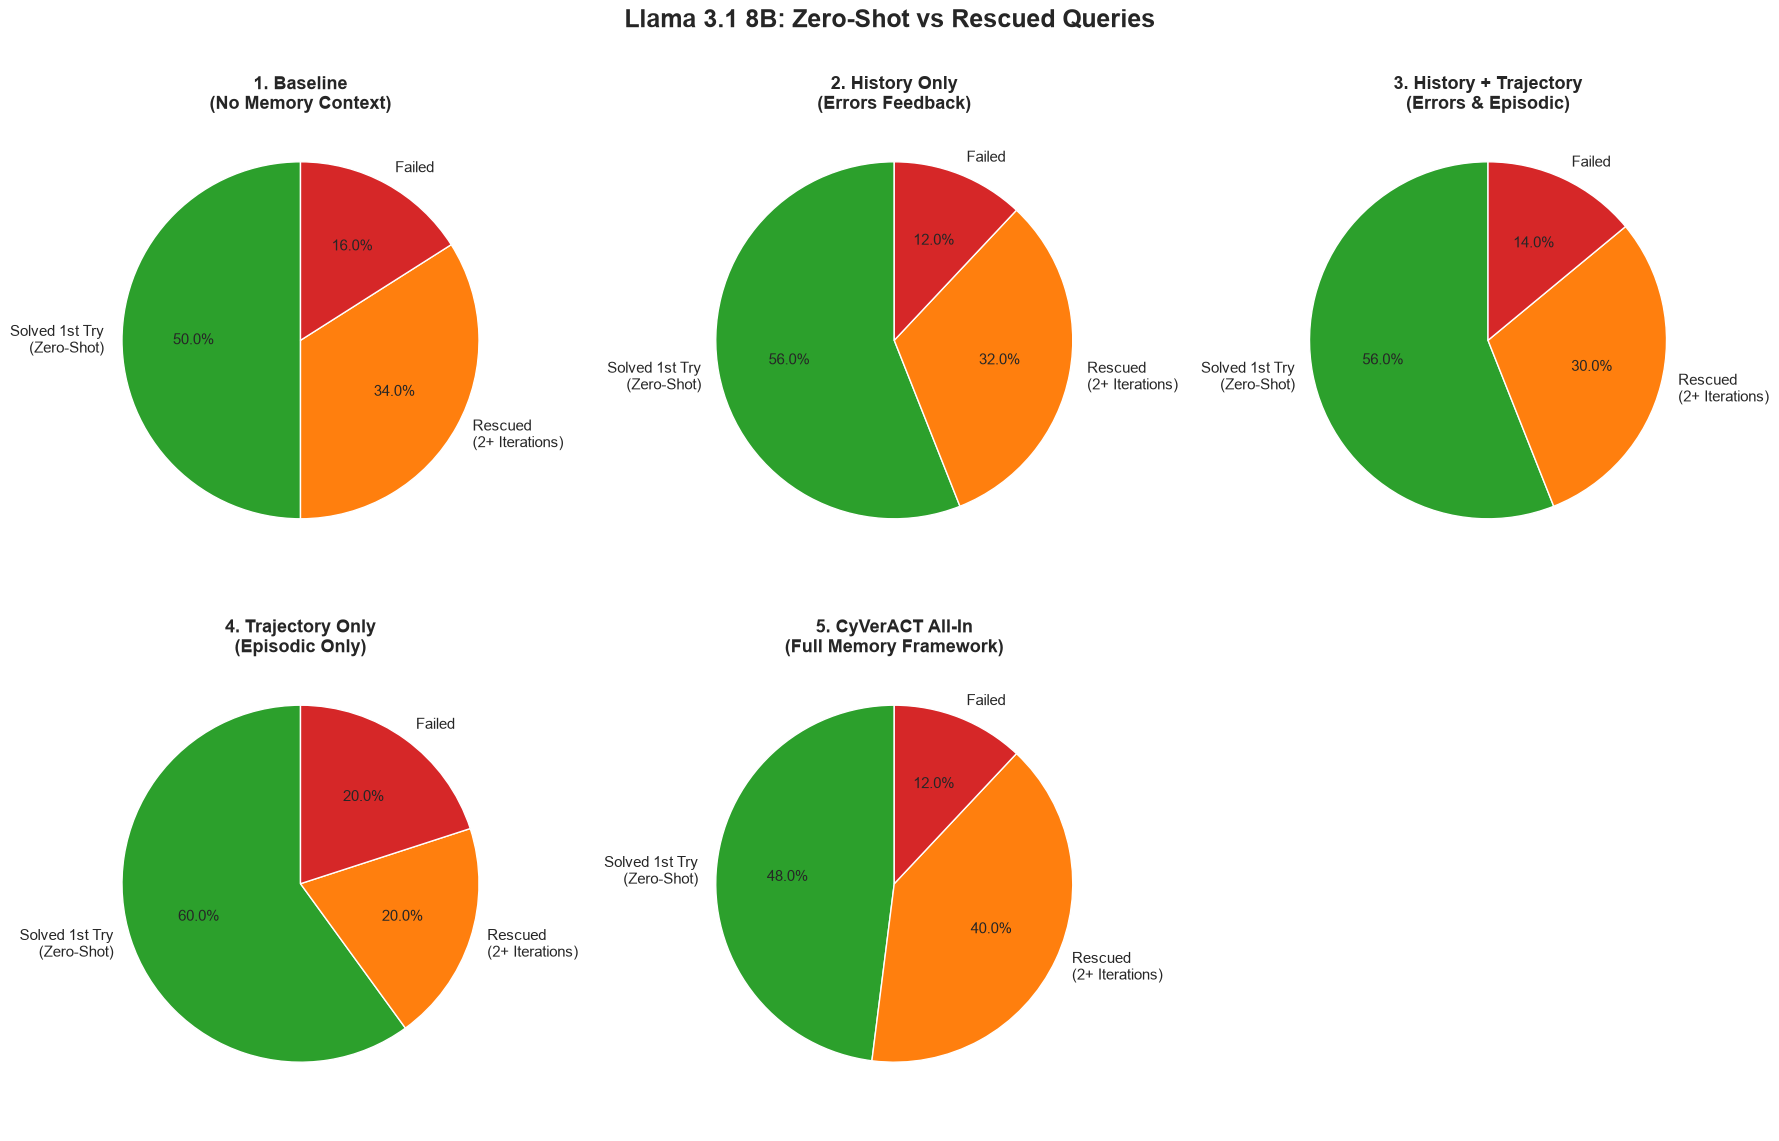

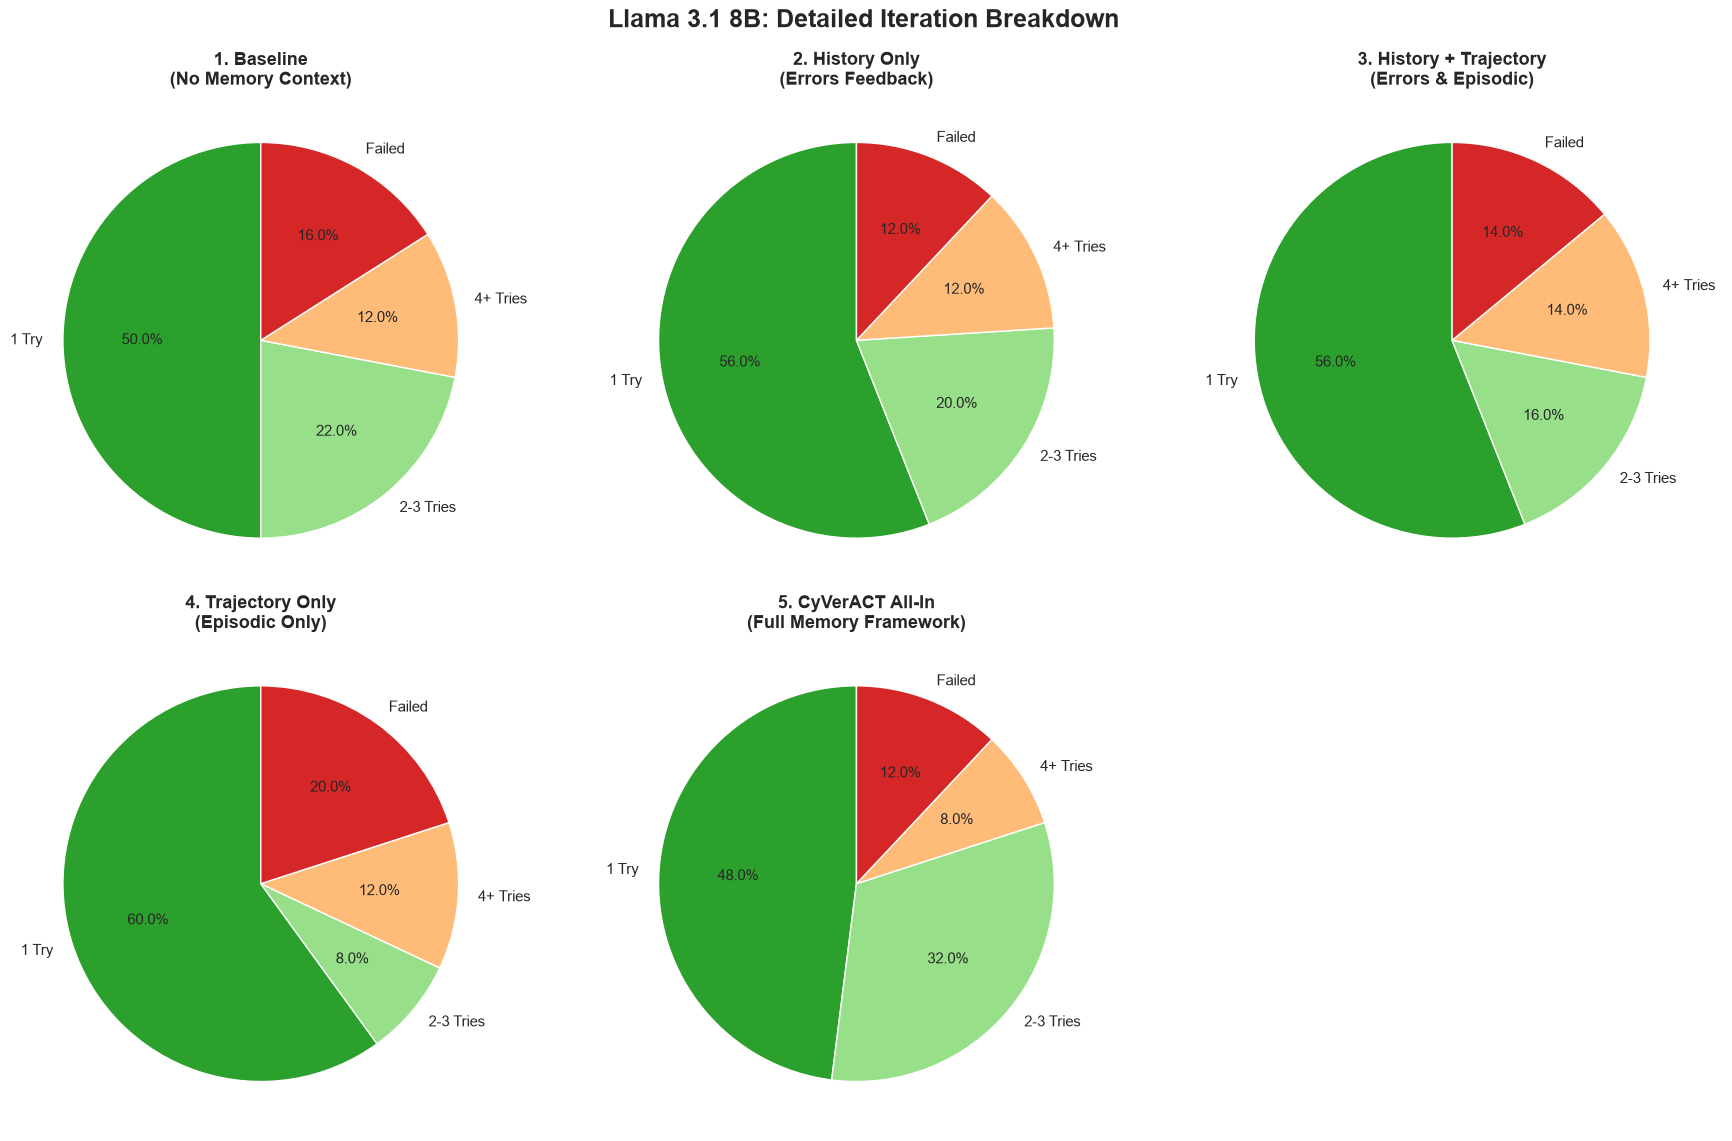

<Figure size 1200x700 with 0 Axes>

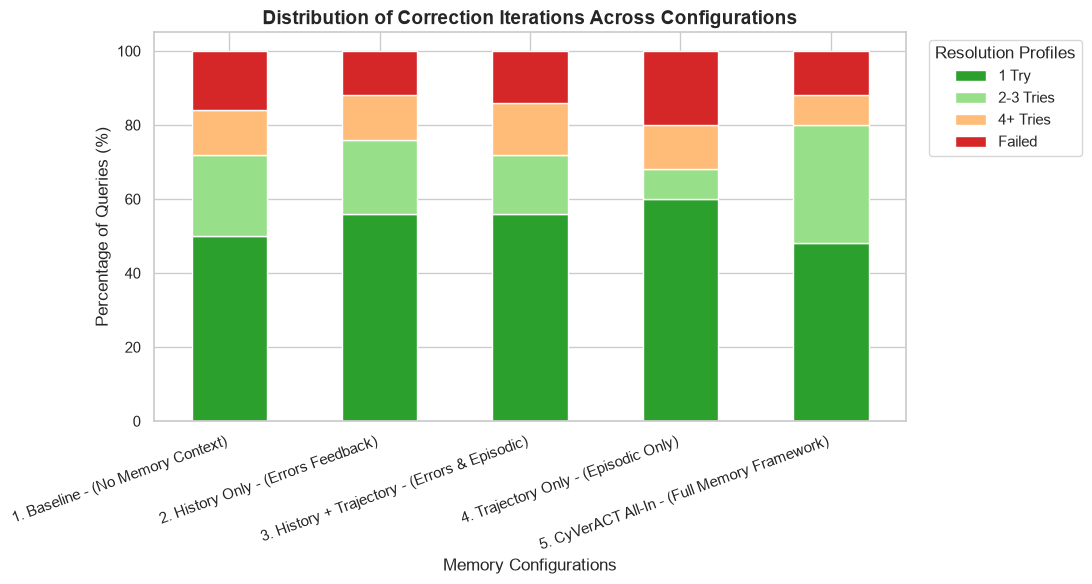

C:\Users\olgag\AppData\Local\Temp\ipykernel_21712\800343001.py:158: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax_lift = sns.barplot(data=lift_df, x='Configuration', y='Accuracy', palette='viridis')


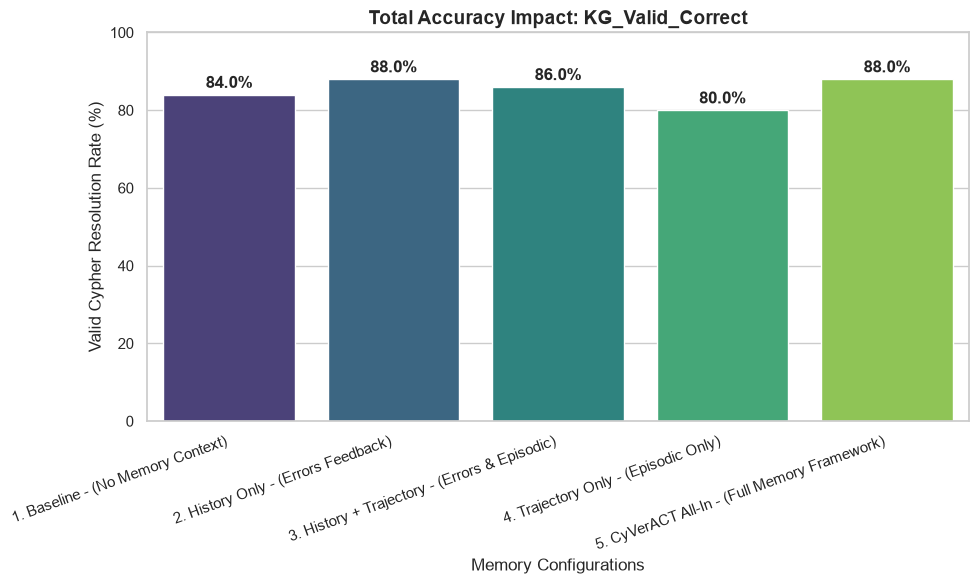

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ==========================================
# 1. LOAD YOUR REVISED DATA PATHS
# ==========================================
# files = {
#     '8B_Baseline': 'Outputs_Evaluation/Movies_Experiment/BASELINE/50testllama3_1_8b_memory_OFF_baseline/50_test_queries_thesis_50testllama3_1_8b_memory_OFF_baseline.xlsx',
#     '8B_History_Only': 'Outputs_Evaluation/Movies_Experiment/HISTORY_ONLY/3llama3_1_8b_memory_OFF/50_test_queries_thesis_3llama3_1_8b_memory_OFF.xlsx', 
#     '8B_History_Trajectory': 'Outputs_Evaluation/Movies_Experiment/HISTORY_TRAJECTORY/2llama3_1_8b_memory_OFF/50_test_queries_thesis_2llama3_1_8b_memory_OFF.xlsx',
#     '8B_Trajectory_Only': 'Outputs_Evaluation/Movies_Experiment/TRAJECTORY_ONLY/4llama3_1_8b_memory_OFF/50_test_queries_thesis_4llama3_1_8b_memory_OFF.xlsx',
#     '8B_All_In': 'Outputs_Evaluation/Movies_Experiment/MEMORY_ALL_IN/llama3_1_8b_memory_OFF/50_test_queries_thesis_llama3_1_8b_memory_OFF.xlsx'  
# }

files = {
    '8B_Baseline': 'Outputs_Evaluation/Movies_Experiment/BASELINE/50testllama3_2_3b_memory_OFF_baseline/50_test_queries_thesis_50testllama3_2_3b_memory_OFF_baseline.xlsx',
    '8B_History_Only': 'Outputs_Evaluation/Movies_Experiment/HISTORY_ONLY/3llama3_2_3b_memory_OFF/50_test_queries_thesis_3llama3_2_3b_memory_OFF.xlsx', 
    '8B_History_Trajectory': 'Outputs_Evaluation/Movies_Experiment/HISTORY_TRAJECTORY/2llama3_2_3b_memory_OFF/50_test_queries_thesis_2llama3_2_3b_memory_OFF.xlsx',
    '8B_Trajectory_Only': 'Outputs_Evaluation/Movies_Experiment/TRAJECTORY_ONLY/4llama3_2_3b_memory_OFF/50_test_queries_thesis_4llama3_2_3b_memory_OFF.xlsx',
    '8B_All_In': 'Outputs_Evaluation/Movies_Experiment/MEMORY_ALL_IN/llama3_2_3b_memory_OFF/50_test_queries_thesis_llama3_2_3b_memory_OFF.xlsx'  
}

# Display titles for the charts so they look clean and academic
display_names = {
    '8B_Baseline': '1. Baseline\n(No Memory Context)',
    '8B_History_Only': '2. History Only\n(Errors Feedback)',
    '8B_History_Trajectory': '3. History + Trajectory\n(Errors & Episodic)',
    '8B_Trajectory_Only': '4. Trajectory Only\n(Episodic Only)',
    '8B_All_In': '5. CyVerACT All-In\n(Full Memory Framework)'
}

dfs = {}
for name, path in files.items():
    try:
        df = pd.read_excel(path)
        # Ensure booleans are cleanly cast for pandas calculations
        df['is_KG_Valid_correct'] = df['is_KG_Valid_correct'].fillna(False).astype(bool)
        dfs[name] = df
    except Exception as e:
        print(f"Error loading file: {name}. Missing path or corrupted data. Details: {e}")

# Proceed only if all 5 requested experiment datasets are successfully loaded
if len(dfs) == len(files):
    sns.set_theme(style="whitegrid")

    # ==========================================
    # PLOT 1: Zero-Shot Success Pie Charts 
    # ==========================================
    fig1, axes1 = plt.subplots(nrows=2, ncols=3, figsize=(18, 12))
    axes1 = axes1.flatten()
    axes1[5].axis('off') 

    def get_rescue_pie_data(df):
        correct = df[df['is_KG_Valid_correct'] == True]
        first_try = len(correct[correct['total_iterations'] == 1])
        rescued = len(correct[correct['total_iterations'] > 1])
        failed = len(df[df['is_KG_Valid_correct'] == False])
        return [first_try, rescued, failed]
        
    labels_rescue = ['Solved 1st Try\n(Zero-Shot)', 'Rescued\n(2+ Iterations)', 'Failed']
    colors_rescue = ['#2ca02c', '#ff7f0e', '#d62728'] # Green, Orange, Red

    for idx, (config_name, df) in enumerate(dfs.items()):
        ax = axes1[idx]
        data = get_rescue_pie_data(df)
        ax.pie(data, labels=labels_rescue, colors=colors_rescue, autopct='%1.1f%%', startangle=90, textprops={'fontsize': 11})
        ax.set_title(display_names[config_name], fontsize=13, fontweight='bold')

    plt.suptitle('Llama 3.1 8B: Zero-Shot vs Rescued Queries', fontsize=18, fontweight='bold', y=0.95)
    plt.tight_layout()
    plt.subplots_adjust(top=0.88)
    plt.savefig('8B_ablation_rescue_pie_charts.png', dpi=300, bbox_inches='tight')
    plt.show()

    # ==========================================
    # PLOT 2: Iteration Distribution Pie Charts (NEW)
    # Shows the exact percentage of 1 try, 2-3 tries, 4+ tries, and failed.
    # ==========================================
    fig2, axes2 = plt.subplots(nrows=2, ncols=3, figsize=(18, 12))
    axes2 = axes2.flatten()
    axes2[5].axis('off') 

    def categorize_iterations(row):
        if not row['is_KG_Valid_correct']:
            return 'Failed'
        elif row['total_iterations'] == 1:
            return '1 Try'
        elif row['total_iterations'] <= 3:
            return '2-3 Tries'
        else:
            return '4+ Tries'

    labels_iter = ['1 Try', '2-3 Tries', '4+ Tries', 'Failed']
    colors_iter = ['#2ca02c', '#98df8a', '#ffbb78', '#d62728'] # Dark Green, Light Green, Orange, Red

    for idx, (config_name, df) in enumerate(dfs.items()):
        ax = axes2[idx]
        
        # Categorize the rows
        df_temp = df.copy()
        df_temp['Bucket'] = df_temp.apply(categorize_iterations, axis=1)
        counts = df_temp['Bucket'].value_counts()
        
        # Ensure the order matches our labels
        data = [counts.get(label, 0) for label in labels_iter]
        
        # Plot the pie chart
        ax.pie(data, labels=labels_iter, colors=colors_iter, autopct='%1.1f%%', startangle=90, textprops={'fontsize': 11})
        ax.set_title(display_names[config_name], fontsize=13, fontweight='bold')

    plt.suptitle('Llama 3.1 8B: Detailed Iteration Breakdown', fontsize=18, fontweight='bold', y=0.95)
    plt.tight_layout()
    plt.subplots_adjust(top=0.88)
    plt.savefig('8B_ablation_iterations_pie_charts.png', dpi=300, bbox_inches='tight')
    plt.show()

    # ==========================================
    # PLOT 3: Ablation Iteration Distribution (Stacked Bar)
    # ==========================================
    dist_data = []
    for config_name in files.keys():
        df = dfs[config_name].copy()
        df['Bucket'] = df.apply(categorize_iterations, axis=1)
        counts = df['Bucket'].value_counts(normalize=True) * 100
        
        display_name = display_names[config_name].replace('\n', ' - ')
        
        dist_data.append({
            'Configuration': display_name,
            '1 Try': counts.get('1 Try', 0),
            '2-3 Tries': counts.get('2-3 Tries', 0),
            '4+ Tries': counts.get('4+ Tries', 0),
            'Failed': counts.get('Failed', 0)
        })

    dist_df = pd.DataFrame(dist_data).set_index('Configuration')
    
    plt.figure(figsize=(12, 7))
    ax = dist_df[['1 Try', '2-3 Tries', '4+ Tries', 'Failed']].plot(
        kind='bar', stacked=True, figsize=(11, 6), 
        color=colors_iter
    )
    plt.title('Distribution of Correction Iterations Across Configurations', fontsize=14, fontweight='bold')
    plt.ylabel('Percentage of Queries (%)', fontsize=12)
    plt.xlabel('Memory Configurations', fontsize=12)
    plt.xticks(rotation=20, ha='right', fontsize=11)
    plt.legend(title='Resolution Profiles', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=11)
    plt.tight_layout()
    plt.savefig('8B_iteration_distribution_stacked.png', dpi=300, bbox_inches='tight')
    plt.show()

    # ==========================================
    # PLOT 4: Comparative Performance Lift across Tiers
    # ==========================================
    lift_data = []
    for config_name in files.keys():
        acc = dfs[config_name]['is_KG_Valid_correct'].mean() * 100
        display_name = display_names[config_name].replace('\n', ' - ')
        lift_data.append({'Configuration': display_name, 'Accuracy': acc})

    lift_df = pd.DataFrame(lift_data)

    plt.figure(figsize=(10, 6))
    ax_lift = sns.barplot(data=lift_df, x='Configuration', y='Accuracy', palette='viridis')
    plt.title('Total Accuracy Impact: KG_Valid_Correct', fontsize=14, fontweight='bold')
    plt.ylabel('Valid Cypher Resolution Rate (%)', fontsize=12)
    plt.xlabel('Memory Configurations', fontsize=12)
    plt.xticks(rotation=20, ha='right', fontsize=11)
    plt.ylim(0, 100)

    for p in ax_lift.patches:
        ax_lift.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold')

    plt.tight_layout()
    plt.savefig('8B_ablation_study_accuracy_lift.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print("Execution Blocked: Please verify that all 5 required Excel files exist in their specified folders before processing charts.")

In [3]:
from dotenv import load_dotenv
import os

from langchain_openai import ChatOpenAI

load_dotenv(override=True)

print("System Initialization")

if not os.getenv("NVIDIA_API_KEY"):
    print("ERROR: NVIDIA_API_KEY missing.")
elif not os.getenv("NEO4J_URI"):
    print("ERROR: NEO4J_URI missing.")
else:
    print("Core API Keys found.")

#model_name = "meta/llama-3.1-8b-instruct"
model_name = "meta/llama-3.2-3b-instruct"

print(f"\nInitializing NVIDIA model: {model_name}...")

model = ChatOpenAI(
    model=model_name,
    api_key=os.getenv("NVIDIA_API_KEY"),
    base_url="https://integrate.api.nvidia.com/v1",
    temperature=0.0,
)

print("Model loaded successfully.")
print("\nSetup Complete! Ready for our agent!")

System Initialization
Core API Keys found.

Initializing NVIDIA model: meta/llama-3.2-3b-instruct...


Model loaded successfully.

Setup Complete! Ready for our agent!


In [4]:
import os
import time
import pandas as pd
import torch
from tqdm import tqdm

def evaluate_model(model_name, model, target_file, save_to_memory=False):
    ''' 
    Evaluates the model using a specific Excel file.
    Forces connection to the stable local Neo4j database.
    Passes 'save_to_memory' to the graph to prevent test data leakage.
    '''
    # Load the specific file from your workflow directory
    file_path = f"C:/Users/olgag/Desktop/agentic-memory/CyVerACT/extended_workflow/{target_file}"
    df = pd.read_excel(file_path)
    
    # Setup Output Directories
    output_dir = f"Outputs_Evaluation/Movies_Experiment/{model_name}/"
    os.makedirs(output_dir, exist_ok=True)

    results_path_pkl = os.path.join(output_dir, f"{target_file.replace('.xlsx', '')}_{model_name}.pkl")
    results_path_xlsx = os.path.join(output_dir, f"{target_file.replace('.xlsx', '')}_{model_name}.xlsx")

    # Resume progress if the file exists
    if os.path.exists(results_path_xlsx):
        print(f"Found existing progress at {results_path_xlsx}. Resuming...")
        df_results = pd.read_excel(results_path_xlsx).astype(object)
    else:
        df_results = df.copy().astype(object)
        new_cols = ['generated_cypher', 'answer', 'path', 'output', 'cypher_errors_history', 
                    'cypher_errors', 'is_KG_Valid_correct', 'total_tokens', 
                    'completion_tokens', 'prompt_tokens', 'is_KG_Valid_correct_with_full_schema',
                    'eval_time_s', 'total_iterations']
        for col in new_cols:
            df_results[col] = None

    config = {
        'configurable': {
            'model': model, 
            'model_name': model_name, 
            'attempts_w_filtered': 5, 
            'total_attempts': 10
        },
        'recursion_limit': 50
    }
    
    print(f'Starting execution on {target_file} | Memory Saving: {save_to_memory}')
    
    for i, row in tqdm(df_results.iterrows(), total=df_results.shape[0]):
        if pd.isna(row['generated_cypher']):
            
            # 🎯 STABLE LOCAL NEO4J CREDENTIALS
            inputs = {
                'question': row['question'] if 'question' in row else row['Question'],
                'database_url': "neo4j://127.0.0.1:7687",
                'database_name': "movies",
                'database_user': "neo4j",          
                'database_password': "agentmemory", 
                'iterations': 0,
                'save_to_memory': save_to_memory   # <--- PASS THE FLAG INTO YOUR GRAPH
            }
            
            result = None
            max_retries = 3
            
            for attempt in range(max_retries):
                try:
                    start = time.perf_counter()
                    result = app.invoke(inputs, config=config)
                    elapsed = time.perf_counter() - start
                    break 
                except Exception as e:
                    print(f"\n⚠️ Error on query {i} (Attempt {attempt+1}): {e}")
                    time.sleep(20)
            
            if result is None:
                continue 
            
            # Record Metrics
            df_results.at[i, 'eval_time_s'] = round(elapsed, 4)
            df_results.at[i, 'generated_cypher'] = result.get('cypher_statement', '')
            df_results.at[i, 'output'] = str(result.get('database_records', ''))
            df_results.at[i, 'path'] = str(result.get('path', []))
            df_results.at[i, 'cypher_errors'] = str(result.get('cypher_errors', []))
            df_results.at[i, 'cypher_errors_history'] = str(result.get('cypher_errors_history', []))
            df_results.at[i, 'is_KG_Valid_correct'] = result.get('is_KG_Valid_correct', False)
            df_results.at[i, 'answer'] = result.get('answer', '')
            df_results.at[i, 'total_tokens'] = str(result.get('total_tokens', ''))
            df_results.at[i, 'total_iterations'] = result.get('iterations', 1)
            
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
                
            df_results.to_pickle(results_path_pkl)
            df_results.to_excel(results_path_xlsx, index=False)

            time.sleep(1) # Fast sleep since database is local
        else:
            print(f"Skipping row {i}, already computed.")
            
    return df_results

In [6]:
# RUN 1: POPULATE MEMORY
model_name = '50testllama3_2_3b_memory_OFF_baseline'

df_memory_results = evaluate_model(
    model_name=model_name, 
    model=model, 
    target_file='50_test_queries_thesis.xlsx',  
    save_to_memory=False                           # <-- MEMORY ON
)

Starting execution on 50_test_queries_thesis.xlsx | Memory Saving: False


  0%|          | 0/50 [00:00<?, ?it/s]

Schema filtering Agent: START
Cypher Generator: START
CyVer Evaluator: START
CyVer Evaluation of MATCH (a:Actor)-[:BORN_IN]->(c:City)<-[:LOCATED_IN]->(d:Country)
WHERE a.bornBefore = true AND d.name = 'United States':


Received notification from DBMS server: <GqlStatusObject gql_status='01N50', status_description='warn: label does not exist. The label `Actor` does not exist in database `movies`. Verify that the spelling is correct.', position=<SummaryInputPosition line=3, column=33, offset=65>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 65, 'line': 3, 'column': 33}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\n                RETURN EXISTS {\n                    MATCH p = (:Actor) \n                } AS path_exists\n            '
Received notification from DBMS server: <GqlStatusObject gql_status='01N50', status_description='warn: label does not exist. The label `City` does not exist in database `movies`. Verify that the spellin


[MEMORY MANAGER] save_to_memory is FALSE. Skipping error recording.

CyVer Errors from generated query:
- Neo.ClientError.Statement.SyntaxError: Query cannot conclude with MATCH (must be a RETURN clause, a FINISH clause, an update clause, a unit subquery call, or a procedure call with no YIELD). (line 1, column 9 (offset: 8))


- Neo.ClientNotification.Statement.UnknownLabelWarning: One of the labels in your query is not available in the database, make sure you didn't misspell it or that the label is available when you run this statement in your application (the missing label name is: Country)

- Neo.ClientNotification.Statement.UnknownRelationshipTypeWarning: One of the relationship types in your query is not available in the database, make sure you didn't misspell it or that the label is available when you run this statement in your application (the missing relationship type is: BORN_IN)

- Neo.ClientNotification.Statement.UnknownLabelWarning: One of the labels in your query is not 

...

Received notification from DBMS server: <GqlStatusObject gql_status='01N52', status_description='warn: property key does not exist. The property `actedIn` does not exist in database `movies`. Verify that the spelling is correct.', position=<SummaryInputPosition line=1, column=42, offset=41>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 41, 'line': 1, 'column': 42}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'RETURN exists { MATCH (x:Movie) WHERE (x.actedIn) IS NOT NULL} AS exists'



[MEMORY MANAGER] save_to_memory is FALSE. Skipping error recording.

CyVer Errors from generated query:
- WrongDirectionPathWarning: The specified path (:Movie)-[:ACTED_IN]->(:Person) has the opposite direction in the knowledge graph schema. The path (m:Movie)-[:ACTED_IN]->(a:Person) in the Cypher statement should be changed to  (m:Movie)<-[:ACTED_IN]-(a:Person).

- Neo.ClientNotification.Statement.UnknownPropertyKeyWarning: One of the property names in your query is not available in the database, make sure you didn't misspell it or that the label is available when you run this statement in your application (the missing property name is: actedIn)

- InvalidPropertyAccessByLabelWarning: The label Movie does not have the following properties:  actedIn.

Schema retriever Agent: START
Cypher Generator: START
CyVer Evaluator: START
CyVer Evaluation of MATCH (p:Person {name: "Nancy Meyers"})-[:DIRECTED]->(m:Movie)-[:ACTED_IN]->(a:Person)
WHERE m.released < 2010
RETURN a.name, m.title, a.rol

 98%|█████████▊| 49/50 [07:15<00:11, 11.05s/it]

Schema filtering Agent: START
Cypher Generator: START
CyVer Evaluator: START
CyVer Evaluation of MATCH (p:Person)-[:ACTED_IN]-(m:Movie)
WITH p, COUNT(DISTINCT m) AS num_movies
WHERE num_movies > 1
RETURN p.name, COUNT(p) AS num_actors, COUNT(DISTINCT p) AS total_people:

[MEMORY MANAGER] save_to_memory is FALSE. Skipping error recording.

Cypher Executor: START
Executing Cypher: MATCH (p:Person)-[:ACTED_IN]-(m:Movie)
WITH p, COUNT(DISTINCT m) AS num_movies
WHERE num_movies > 1
RETURN p.name, COUNT(p) AS num_actors, COUNT(DISTINCT p) AS total_people
Records found: 35

[MEMORY MANAGER] save_to_memory is FALSE. Skipping successful pattern storage.

Cypher Executor: END
Output Generator: START
Agent Answer: I found the following in the database: p.name: Keanu Reeves, num_actors: 1, total_people: 1 | p.name: Carrie-Anne Moss, num_actors: 1, total_people: 1 | p.name: Laurence Fishburne, num_actors: 1, total_people: 1 | p.name: Hugo Weaving, num_actors: 1, total_people: 1 | p.name: Charlize T

100%|██████████| 50/50 [07:18<00:00,  8.77s/it]


In [6]:
import pandas as pd
import numpy as np

# Load files
df_on = pd.read_excel('Outputs_Evaluation/Movies_Experiment/llama3_1_8b_memory_ON/50_memory_queries_thesis_llama3_1_8b_memory_ON.xlsx')
df_off = pd.read_excel('Outputs_Evaluation/Movies_Experiment/llama3_1_8b_memory_OFF/50_test_queries_thesis_llama3_1_8b_memory_OFF.xlsx')

# Convert boolean columns properly
for df in [df_on, df_off]:
    df['is_KG_Valid_correct'] = df['is_KG_Valid_correct'].fillna(False).astype(bool)

print(f"Memory ON Run - Executable Cypher Validity: {df_on['is_KG_Valid_correct'].mean() * 100:.2f}%")
print(f"Memory OFF Run - Executable Cypher Validity: {df_off['is_KG_Valid_correct'].mean() * 100:.2f}%")

Memory ON Run - Executable Cypher Validity: 82.00%
Memory OFF Run - Executable Cypher Validity: 88.00%


C:\Users\olgag\AppData\Local\Temp\ipykernel_21788\1341803809.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['First 25 Queries (Empty Memory)', 'Last 25 Queries (Built Memory)'], y=[fh_valid, sh_valid], ax=ax1, palette='vlag')
C:\Users\olgag\AppData\Local\Temp\ipykernel_21788\1341803809.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['First 25 Queries', 'Last 25 Queries'], y=[fh_iter, sh_iter], ax=ax2, palette='deep')


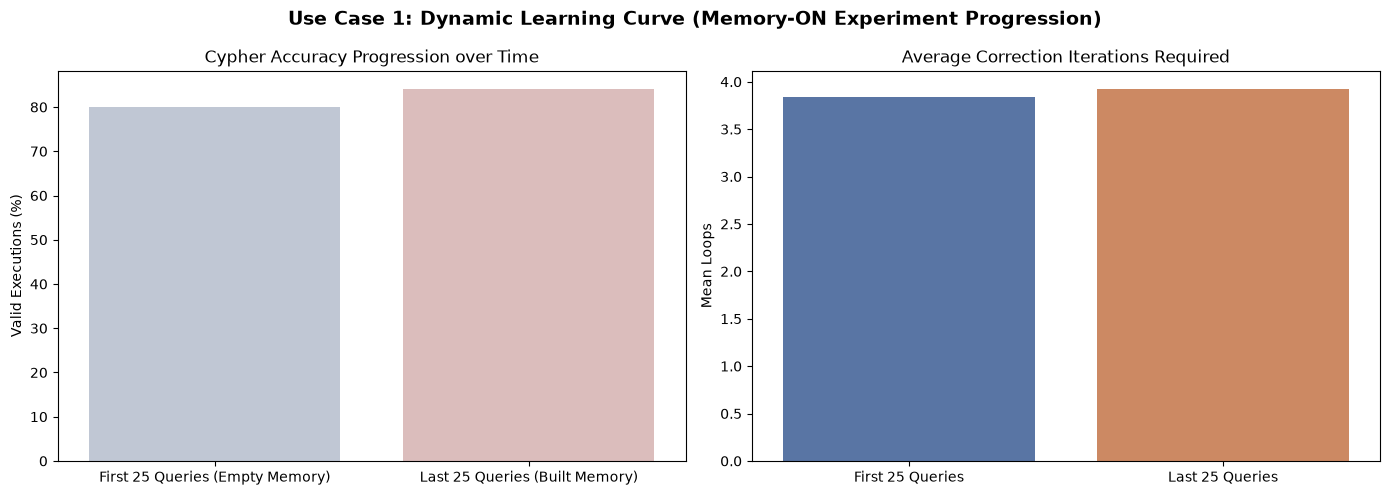

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Split the Memory ON dataset into first half (learning) and second half (exploiting)
first_half = df_on.head(25)
second_half = df_on.tail(25)

fh_valid = first_half['is_KG_Valid_correct'].mean() * 100
sh_valid = second_half['is_KG_Valid_correct'].mean() * 100

fh_iter = first_half['total_iterations'].mean()
sh_iter = second_half['total_iterations'].mean()

# Plotting Sequential Progression
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=['First 25 Queries (Empty Memory)', 'Last 25 Queries (Built Memory)'], y=[fh_valid, sh_valid], ax=ax1, palette='vlag')
ax1.set_title('Cypher Accuracy Progression over Time')
ax1.set_ylabel('Valid Executions (%)')

sns.barplot(x=['First 25 Queries', 'Last 25 Queries'], y=[fh_iter, sh_iter], ax=ax2, palette='deep')
ax2.set_title('Average Correction Iterations Required')
ax2.set_ylabel('Mean Loops')

plt.suptitle('Use Case 1: Dynamic Learning Curve (Memory-ON Experiment Progression)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

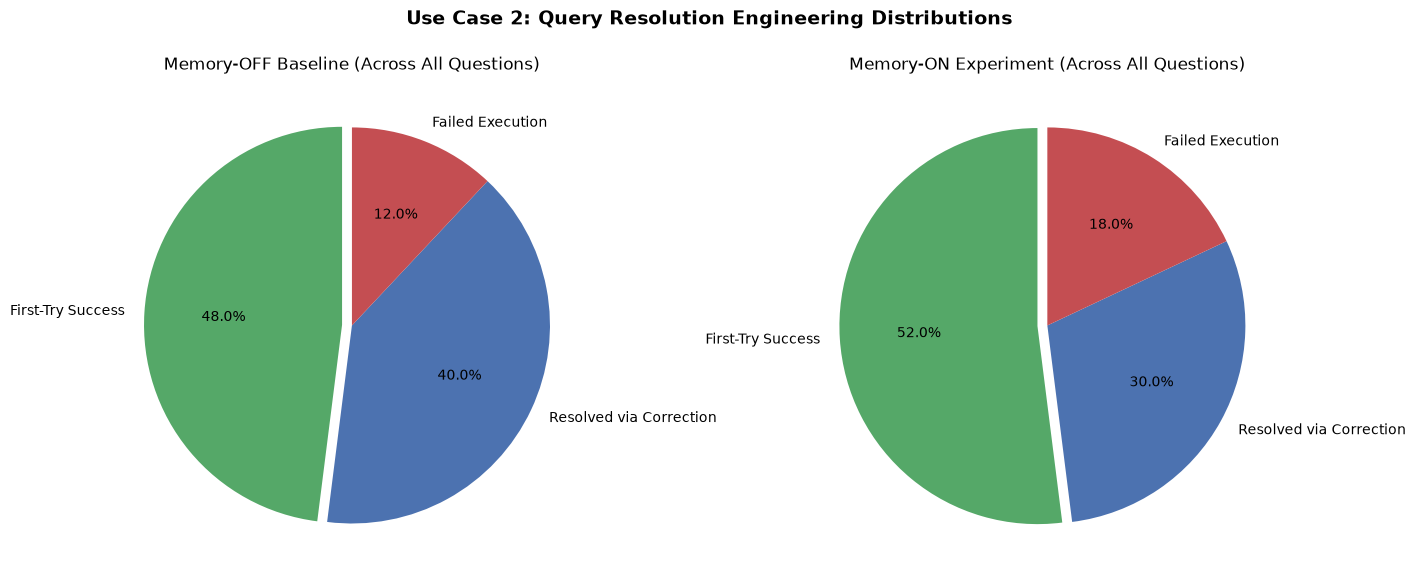

In [8]:
def get_pie_slices(df):
    first_try = df[df['total_iterations'] == 1].shape[0]
    corrected = df[(df['total_iterations'] > 1) & (df['is_KG_Valid_correct'] == True)].shape[0]
    failed = df[df['is_KG_Valid_correct'] == False].shape[0]
    return [first_try, corrected, failed]

labels = ['First-Try Success', 'Resolved via Correction', 'Failed Execution']
colors = ['#55A868', '#4C72B0', '#C44E52']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.pie(get_pie_slices(df_off), labels=labels, autopct='%1.1f%%', startangle=90, colors=colors, explode=(0.05, 0, 0))
ax1.set_title('Memory-OFF Baseline (Across All Questions)')

ax2.pie(get_pie_slices(df_on), labels=labels, autopct='%1.1f%%', startangle=90, colors=colors, explode=(0.05, 0, 0))
ax2.set_title('Memory-ON Experiment (Across All Questions)')

plt.suptitle('Use Case 2: Query Resolution Engineering Distributions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

C:\Users\olgag\AppData\Local\Temp\ipykernel_21788\3495286493.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['First 25 Queries (Empty Memory)', 'Last 25 Queries (Populated Memory)'], y=[fh_valid, sh_valid], ax=ax1, palette='vlag')
C:\Users\olgag\AppData\Local\Temp\ipykernel_21788\3495286493.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['First 25 Queries', 'Last 25 Queries'], y=[fh_iter, sh_iter], ax=ax2, palette='deep')


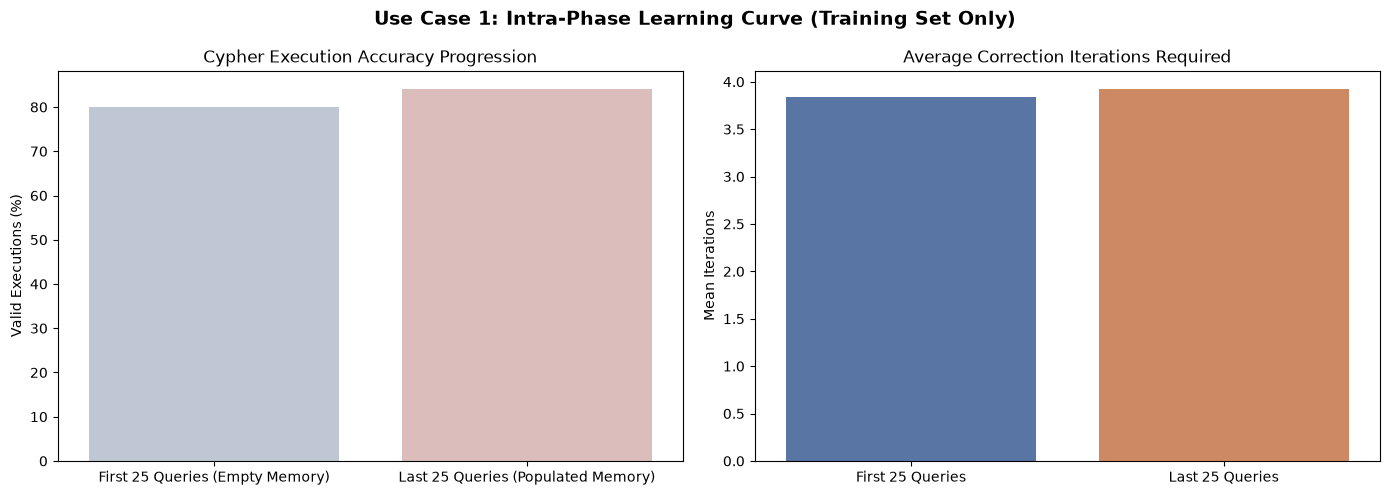

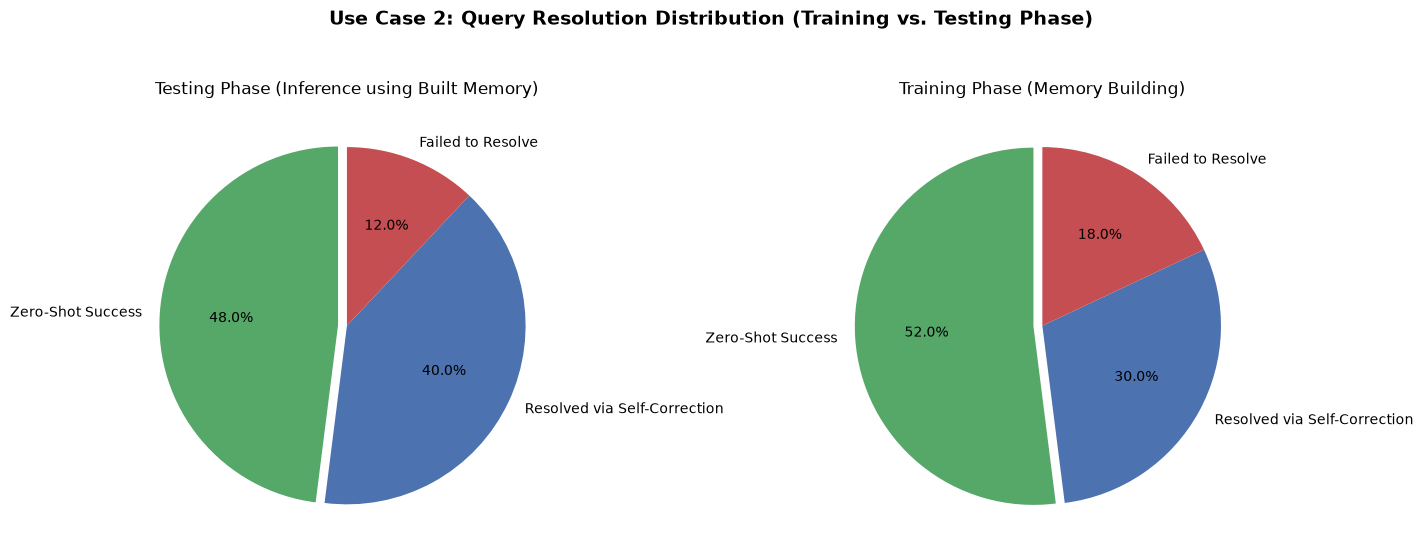

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Load your two 50-query split files
df_training = pd.read_excel('Outputs_Evaluation/Movies_Experiment/llama3_1_8b_memory_ON/50_memory_queries_thesis_llama3_1_8b_memory_ON.xlsx')
df_testing = pd.read_excel('Outputs_Evaluation/Movies_Experiment/llama3_1_8b_memory_OFF/50_test_queries_thesis_llama3_1_8b_memory_OFF.xlsx')

# Ensure booleans
df_training['is_KG_Valid_correct'] = df_training['is_KG_Valid_correct'].fillna(False).astype(bool)
df_testing['is_KG_Valid_correct'] = df_testing['is_KG_Valid_correct'].fillna(False).astype(bool)

# ========================================================
# PLOT 1: The Learning Curve (Bar Charts)
# ========================================================
first_half = df_training.head(25)
second_half = df_training.tail(25)

fh_valid = first_half['is_KG_Valid_correct'].mean() * 100
sh_valid = second_half['is_KG_Valid_correct'].mean() * 100
fh_iter = first_half['total_iterations'].mean()
sh_iter = second_half['total_iterations'].mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=['First 25 Queries (Empty Memory)', 'Last 25 Queries (Populated Memory)'], y=[fh_valid, sh_valid], ax=ax1, palette='vlag')
ax1.set_title('Cypher Execution Accuracy Progression')
ax1.set_ylabel('Valid Executions (%)')

sns.barplot(x=['First 25 Queries', 'Last 25 Queries'], y=[fh_iter, sh_iter], ax=ax2, palette='deep')
ax2.set_title('Average Correction Iterations Required')
ax2.set_ylabel('Mean Iterations')

plt.suptitle('Use Case 1: Intra-Phase Learning Curve (Training Set Only)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ========================================================
# PLOT 2: Problem Resolution Distribution (Pie Charts)
# ========================================================
def get_pie_slices(df):
    first_try = df[df['total_iterations'] == 1].shape[0]
    corrected = df[(df['total_iterations'] > 1) & (df['is_KG_Valid_correct'] == True)].shape[0]
    failed = df[df['is_KG_Valid_correct'] == False].shape[0]
    return [first_try, corrected, failed]

labels = ['Zero-Shot Success', 'Resolved via Self-Correction', 'Failed to Resolve']
colors = ['#55A868', '#4C72B0', '#C44E52']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Right Chart is now the Training Phase
ax2.pie(get_pie_slices(df_training), labels=labels, autopct='%1.1f%%', startangle=90, colors=colors, explode=(0.05, 0, 0))
ax2.set_title('Training Phase (Memory Building)')

# Left Chart is the Testing Phase
ax1.pie(get_pie_slices(df_testing), labels=labels, autopct='%1.1f%%', startangle=90, colors=colors, explode=(0.05, 0, 0))
ax1.set_title('Testing Phase (Inference using Built Memory)')

plt.suptitle('Use Case 2: Query Resolution Distribution (Training vs. Testing Phase)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# RUN ONCE 

import nltk

# Dowloading these for NLTK
print("Downloading NLTK data...")
nltk.download('stopwords')
nltk.download('punkt')      
nltk.download('punkt_tab')  
print("Done! You can now run your agent.")

In [9]:
# CLEANING UP COGNEE 
import cognee

# Remove all user data (datasets, documents)
await cognee.prune.prune_data()

# Remove all system data (graph, vectors, metadata, cache)
await cognee.prune.prune_system(metadata=True)


2026-05-07T13:26:34.634565 [info     ] Database deleted successfully. [cognee.shared.logging_utils]

Storage manager absolute path: C:\Users\olgag\Desktop\agentic-memory\venv\Lib\site-packages\cognee\.cognee_cache

Deleting cache...             

✓ Cache deleted successfully! 


TESTING WITH MOVIES DB

In [2]:
# Loading .env
load_dotenv(override=True) 

print("System Initialization")

# Key Checks
if not os.getenv("OPENAI_API_KEY"):
    print("WARNING: OPENAI_API_KEY missing.")
elif not os.getenv("HUGGINGFACE_API_KEY"):
    print("ERROR: HUGGINGFACE_API_KEY missing.")
elif not os.getenv("NEO4J_URI"):
    print("ERROR: NEO4J URI missing.")
else:
    print("Core API Keys found.")

# Model Settings
model_name = "meta-llama/Meta-Llama-3.1-8B-Instruct"

print(f"\nInitializing Hugging Face model: {model_name}...")

try:
    hf_endpoint = HuggingFaceEndpoint(
        repo_id=model_name, 
        task="text-generation",
        max_new_tokens=512,
        temperature=0.0, 
        huggingfacehub_api_token=os.getenv("HUGGINGFACE_API_KEY")
    )

    model = ChatHuggingFace(llm=hf_endpoint)
    print(f"Model {model_name} loaded successfully.")
    
except Exception as e:
    print(f"Error loading model: {e}")

# Config Settings
config = {
    'configurable': {
        'model': model, 
        'model_name': model_name, 
        'total_attempts': 5,          # total 
        'attempts_w_filtered': 3,     # with filtered
    },
    'recursion_limit': 50
}

# Setting up inputs for next cell
inputs = {
    'database_url': os.getenv("NEO4J_URI"),           
    'database_name': "movies",                        
    'database_user': os.getenv("NEO4J_USERNAME"),    
    'database_password': os.getenv("NEO4J_PASSWORD")  
}

print("\nSetup Complete! Ready for our agent!")

System Initialization
Core API Keys found.

Initializing Hugging Face model: meta-llama/Meta-Llama-3.1-8B-Instruct...
Model meta-llama/Meta-Llama-3.1-8B-Instruct loaded successfully.

Setup Complete! Ready for our agent!


In [3]:
# THE 10-QUERY CONDENSED DATASET
custom_dataset = [
    {"question": "Find all actors who acted in more than 5 movies", "correct_cypher": "MATCH (a:Person)-[:ACTED_IN]->(m:Movie) WITH a, count(m) AS movie_count WHERE movie_count > 5 RETURN a.name"},
    {"question": "Find movies that have more than 2 actors", "correct_cypher": "MATCH (m:Movie)<-[:ACTED_IN]-(a:Person) WITH m, count(a) AS actor_count WHERE actor_count > 2 RETURN m.title"},
    {"question": "Find actors who acted in movies directed by Tom Hanks", "correct_cypher": "MATCH (a:Person)-[:ACTED_IN]->(m:Movie)<-[:DIRECTED]-(d:Person {name: 'Tom Hanks'}) RETURN DISTINCT a.name"},
    {"question": "Find all directors who directed at least 1 movie", "correct_cypher": "MATCH (d:Person)-[:DIRECTED]->(m:Movie) WITH d, count(m) AS movie_count WHERE movie_count >= 1 RETURN d.name"},
    {"question": "Find all actors who acted in Stand By Me", "correct_cypher": "MATCH (a:Person)-[:ACTED_IN]->(m:Movie {title: 'The Matrix'}) RETURN a.name"}
]

print(f"Loaded condensed dataset with {len(custom_dataset)} queries")

Loaded condensed dataset with 5 queries


In [3]:
# THE 10-QUERY CONDENSED DATASET
custom_dataset = [
    {"question": "Find all actors who acted in more than 3 movies", "correct_cypher": "MATCH (a:Person)-[:ACTED_IN]->(m:Movie) WITH a, count(m) AS movie_count WHERE movie_count > 3 RETURN a.name"},
    {"question": "Find actors and how many distinct movies they acted in", "correct_cypher": "MATCH (a:Person)-[:ACTED_IN]->(m:Movie) RETURN a.name, count(DISTINCT m) AS movie_count"},
    {"question": "Find movies that have more than 3 actors", "correct_cypher": "MATCH (m:Movie)<-[:ACTED_IN]-(a:Person) WITH m, count(a) AS actor_count WHERE actor_count > 3 RETURN m.title"},
    {"question": "Find actors who acted in movies directed by Ron Howard", "correct_cypher": "MATCH (a:Person)-[:ACTED_IN]->(m:Movie)<-[:DIRECTED]-(d:Person {name: 'Ron Howard'}) RETURN DISTINCT a.name"},
    {"question": "Find actors who acted in exactly one movie", "correct_cypher": "MATCH (a:Person)-[:ACTED_IN]->(m:Movie) WITH a, count(m) AS movie_count WHERE movie_count = 1 RETURN a.name"},
    {"question": "Find all directors who directed at least 2 movies", "correct_cypher": "MATCH (d:Person)-[:DIRECTED]->(m:Movie) WITH d, count(m) AS movie_count WHERE movie_count >= 2 RETURN d.name"},
    {"question": "Find all people who both acted in and directed movies", "correct_cypher": "MATCH (p:Person)-[:ACTED_IN]->(:Movie), (p)-[:DIRECTED]->(:Movie) RETURN DISTINCT p.name"},
    {"question": "Find all actors who acted in The Matrix", "correct_cypher": "MATCH (a:Person)-[:ACTED_IN]->(m:Movie {title: 'The Matrix'}) RETURN a.name"},
    {"question": "Find how many movies were released per year", "correct_cypher": "MATCH (m:Movie) WHERE m.released IS NOT NULL RETURN m.released, count(m) AS movie_count"},
    {"question": "Return each movie along with its director", "correct_cypher": "MATCH (m:Movie)<-[:DIRECTED]-(d:Person) RETURN m.title, d.name"}
]

print(f"Loaded condensed dataset with {len(custom_dataset)} queries")

Loaded condensed dataset with 10 queries


In [4]:
import time
import pandas as pd
from tqdm import tqdm

print("Starting evaluation for custom_dataset on Movies DB...")
evaluation_results = [] 

# 1. CHANGE THE CONFIG NAME FOR THE EXCEL EXPORT
config_name = "CUSTOM_MEMORY" 

for i, data in enumerate(tqdm(custom_dataset, desc="Evaluating Queries")):
    question = data["question"]
    correct_cypher = data["correct_cypher"]
    
    print('\n' + '#' * 60)
    print(f" QUERY {i+1}: {question}")
    print('#' * 60)
    
    inputs['question'] = question
    start_time = time.time()
    
    try:
        # RUN THE LANGGRAPH STATE
        result = app.invoke(inputs, config=config)
        latency = time.time() - start_time
        
        answer = result.get('answer', "No answer provided")
        final_cypher = result.get('cypher_statement', "") 
        
        print('\n' + '='*50)
        print(f"Final Agent Answer: {answer}")
        print('='*50 + '\n')
        
        # EXTRACT METRICS FROM THE STATE
        evaluation_results.append({
            "Configuration": config_name,
            "Question_ID": i + 1,
            "Question": question,
            "Correct_Cypher": correct_cypher,
            "Generated_Cypher": final_cypher,
            "VCR_KG_Valid": result.get("is_valid_cypher", False), 
            "First_Try_Success": result.get("attempts", 1) == 1,
            "Correction_Attempts": result.get("attempts", 1) - 1,
            # Force these to False for the baseline run just to be safe
            "Total_Invocations": result.get("llm_invocations", 1),
            "Total_Tokens": result.get("total_tokens", 0),
            "Latency_Seconds": round(latency, 2),
            "Status": "Success",
            "Error_Log": ""
        })
        
    except Exception as e:
        latency = time.time() - start_time
        print(f"\n Execution Failed: {e}")
        evaluation_results.append({
            "Configuration": config_name,
            "Question_ID": i + 1,
            "Question": question,
            "Correct_Cypher": correct_cypher,
            "Generated_Cypher": "",
            "VCR_KG_Valid": False, 
            "First_Try_Success": False,
            "Correction_Attempts": 0,
            "Total_Invocations": 1,
            "Total_Tokens": 0,
            "Latency_Seconds": round(latency, 2),
            "Status": "Failed",
            "Error_Log": str(e)
        })
    
    # Adding a small buffer to respect API rate limits
    if i < len(custom_dataset) - 1:
        print("Waiting 5s for API rate limits...")
        time.sleep(5)

print("\n Evaluation Complete! Exporting to Excel...")

# EXPORT TO EXCEL
df = pd.DataFrame(evaluation_results)
file_name = f"movies_db_metrics_{config_name}.xlsx"
df.to_excel(file_name, index=False, engine='openpyxl')
print(f"Metrics successfully exported to {file_name}!")

Starting evaluation for custom_dataset on Movies DB...


Evaluating Queries:   0%|          | 0/5 [00:00<?, ?it/s]


############################################################
 QUERY 1: Find all actors who acted in more than 5 movies
############################################################
Schema filtering Agent: START
Cypher Generator: START
CyVer Evaluator: START
CyVer Evaluation of MATCH (p:Person)-[:ACTED_IN]->(m:Movie) GROUP BY p MATCH (p) WHERE size((p)-[:ACTED_IN]->(m)) > 5 RETURN p:
CyVer Errors from generated query:
- Neo.ClientError.Statement.SyntaxError: Invalid input 'GROUP': expected a graph pattern, ',', 'ORDER BY', 'CALL', 'CREATE', 'LOAD CSV', 'DELETE', 'DETACH', 'FILTER', 'FINISH', 'FOREACH', 'INSERT', 'LET', 'LIMIT', 'MATCH', 'MERGE', 'NEXT', 'NODETACH', 'OFFSET', 'OPTIONAL', 'REMOVE', 'RETURN', 'SEARCH', 'SET', 'SKIP', 'UNION', 'UNWIND', 'USE', 'USING', 'WHERE', 'WITH' or <EOF> (line 1, column 49 (offset: 48))



[MEMORY MANAGER] Triggered! Retrieved the following FixRules:
   -> Strictly adhere to valid query syntax (e.g., standard Cypher). Do not hallucinate unsupported cl

Evaluating Queries:  20%|██        | 1/5 [00:19<01:19, 19.94s/it]


############################################################
 QUERY 2: Find movies that have more than 2 actors
############################################################
Schema filtering Agent: START

 Execution Failed: 402 Client Error: Payment Required for url: https://router.huggingface.co/novita/v3/openai/chat/completions (Request ID: Root=1-6a4d2a3d-1478a781536d2687399e0886;13ca94ab-e901-4f21-a1fa-56f0c24ff882)

You have depleted your monthly included credits. Purchase pre-paid credits to continue using Inference Providers. Alternatively, subscribe to PRO to get 20x more included usage.
Waiting 5s for API rate limits...


Evaluating Queries:  20%|██        | 1/5 [00:27<01:49, 27.31s/it]


KeyboardInterrupt: 

In [7]:
import json

# --- 1. EVALUATION FUNCTIONS ---

def extract_values(record):
    """Recursively pulls out primitive values from a dictionary, ignoring all keys."""
    values = []
    if isinstance(record, dict):
        for v in record.values():
            if isinstance(v, dict):
                values.extend(extract_values(v))
            else:
                values.append(v)
    else:
        values.append(record)
    return values

def is_sub_record(gt_vals, gen_vals):
    """Checks if all values in a Ground Truth record exist somewhere in the Generated record."""
    temp_gen = list(gen_vals)
    for v in gt_vals:
        if v in temp_gen:
            temp_gen.remove(v) # Safely handle duplicate values
        else:
            return False
    return True

def calculate_accuracy(generated_records, ground_truth_records):
    """
    Execution Accuracy: Validates that every Ground Truth record is satisfied
    by a Generated record (even if the generated record has extra properties).
    """
    # Handle empty returns
    if not generated_records or not ground_truth_records:
        return generated_records == ground_truth_records
        
    # If the queries returned a different number of rows
    if len(generated_records) != len(ground_truth_records):
        return False

    # Extract all values as strings
    gen_rows = [[str(v) for v in extract_values(rec)] for rec in generated_records]
    gt_rows = [[str(v) for v in extract_values(rec)] for rec in ground_truth_records]

    # Map each Ground Truth row to a Generated row
    matched_gen_indices = set()
    for gt_row in gt_rows:
        match_found = False
        for i, gen_row in enumerate(gen_rows):
            if i in matched_gen_indices:
                continue # Row already used
                
            # If the GT values are a subset of the Generated values for this row
            if is_sub_record(gt_row, gen_row):
                matched_gen_indices.add(i)
                match_found = True
                break
                
        if not match_found:
            return False # A ground truth record was missing from the generated results!

    return True


# --- 2. EXECUTION LOGIC ---

file_path = 'baseline_no_memory_results.json' 

try:
    with open(file_path, 'r', encoding='utf-8') as file:
        eval_data = json.load(file)

    total_queries = len(eval_data)
    correct_executions = 0

    print(f"--- RUNNING TEXT2CYPHER EXECUTION ACCURACY EVALUATION ({total_queries} Queries) ---\n")

    for item in eval_data:
        q_id = item['id']
        
        # Calculate Execution Accuracy
        is_accurate = calculate_accuracy(
            item['generated_records'], 
            item['correct_records'] 
        )
        if is_accurate:
            correct_executions += 1
            
        print(f"Query [{q_id}]: Execution Match: {is_accurate}")

    # Final Aggregated Metric
    if total_queries > 0:
        execution_accuracy_percentage = (correct_executions / total_queries) * 100

        print("\n--- FINAL METRICS ---")
        print(f"Execution Accuracy: {execution_accuracy_percentage:.2f}% ({correct_executions}/{total_queries})")
    else:
        print("No queries found in the JSON file.")

except FileNotFoundError:
    print(f"Error: Could not find '{file_path}'. Make sure it is in the same folder as your notebook!")
except json.JSONDecodeError as e:
    print(f"Error: Your JSON file is not formatted correctly. Please check for syntax errors. Details: {e}")

--- RUNNING TEXT2CYPHER EXECUTION ACCURACY EVALUATION (10 Queries) ---

Query [1]: Execution Match: True
Query [2]: Execution Match: True
Query [3]: Execution Match: False
Query [4]: Execution Match: False
Query [5]: Execution Match: False
Query [6]: Execution Match: True
Query [7]: Execution Match: False
Query [8]: Execution Match: True
Query [9]: Execution Match: True
Query [10]: Execution Match: True

--- FINAL METRICS ---
Execution Accuracy: 60.00% (6/10)


CUSTOM MEMORY EXPERIMENT

In [1]:
# IMPORTS
from graph import app 
import pandas as pd
import os
from tqdm.auto import tqdm
import torch
import time 
from Configuration.models import models #import models to evaluate
from dotenv import load_dotenv
from langchain_huggingface import ChatHuggingFace, HuggingFaceEndpoint
from langchain_openai import ChatOpenAI
from langchain_neo4j import Neo4jGraph  # for schema
from langchain_ollama import ChatOllama
from Agent_Memory.memory_manager import log_episode_to_memory

In [2]:
# Loading .env
load_dotenv(override=True) 

print("System Initialization")

# Key Checksss
if not os.getenv("OPENAI_API_KEY"):
    print("ERROR: OPENAI_API_KEY missing.")
elif not os.getenv("HUGGINGFACE_API_KEY"):
    print("ERROR: HUGGINGFACE_API_KEY missing.")
elif not os.getenv("NEO4J_URI"):
    print("ERROR: NEO4J URI missing.")
else:
    print("All API Keys found.")

model_name = "meta-llama/Meta-Llama-3.1-8B-Instruct"

print(f"\nInitializing Hugging Face model: {model_name}...")

try:
    hf_endpoint = HuggingFaceEndpoint(
        repo_id=model_name, 
        task="text-generation",
        max_new_tokens=512,
        temperature=0.1, 
        huggingfacehub_api_token=os.getenv("HUGGINGFACE_API_KEY")
    )

    model = ChatHuggingFace(llm=hf_endpoint)
    print(f"Model {model_name} loaded successfully.")
    
except Exception as e:
    print(f"Error loading model: {e}")

# Config Settings
config = {
    'configurable': {
        'model': model, 
        'model_name': model_name, 
        'total_attempts': 5,          # total 
        'attempts_w_filtered': 3,     # with filtered
    },
    'recursion_limit': 50
}

# Setting up inputs for next cell
inputs = {
    'database_url': os.getenv("NEO4J_URI"),           
    'database_name': "movies",                        
    'database_user': os.getenv("NEO4J_USERNAME"),    
    'database_password': os.getenv("NEO4J_PASSWORD")  
}


print("\nSetup Complete! Ready for our agent!")

System Initialization
All API Keys found.

Initializing Hugging Face model: meta-llama/Meta-Llama-3.1-8B-Instruct...
Model meta-llama/Meta-Llama-3.1-8B-Instruct loaded successfully.

Setup Complete! Ready for our agent!


In [ ]:
custom_dataset = [
    "Find all actors who act in more than 3 movies",
    "Find actors and how many distinct movies they are acting in",
    "Find movies that have more than 3 actors"
]

print("Running custom_dataset on Movies DB...")
results_log = [] 

memory_uri = os.getenv("NEO4J_URI")
memory_user = os.getenv("NEO4J_USERNAME")
memory_pw = os.getenv("NEO4J_PASSWORD")

for i, question in enumerate(tqdm(custom_dataset)):
    print('\n' + '#' * 60)
    print(f" QUERY {i+1}: {question}")
    print('#' * 60)
    
    inputs['question'] = question
    
    try:
        result = app.invoke(inputs, config=config)
        
        # Formatting
        print('\n' + '='*50)
        print(f"Final Agent Answer: {result.get('answer', 'No answer generated.')}")
        print('='*50 + '\n')
        
        if i < len(custom_dataset) - 1:
            print("Waiting 10s for API rate limits...")
            time.sleep(10)

    except Exception as e:
        print(f"Execution Failed: {e}")

END OF CUSTOM MEMORY EXPERIMENT

END OF TESTING WITH MOVIES DB

In [ ]:
# Loading .env
load_dotenv(override=True) 

print("System Initialization")

# Key Checksss
if not os.getenv("OPENAI_API_KEY"):
    print("ERROR: OPENAI_API_KEY missing.")
#elif not os.getenv("GROQ_API_KEY"):
    #print("ERROR: GROQ_API_KEY missing. Check your .env file.")
elif not os.getenv("HUGGINGFACE_API_KEY"):
    print("ERROR: HUGGINGFACE_API_KEY missing.")
elif not os.getenv("NEO4J_URI"):
    print("ERROR: NEO4J URI missing.")
else:
    print("All API Keys found.")

# # HYBRID MEMORY Init
# memory = None
# try:
#     from Memory.hybrid_manager import HybridMemoryManager
#     print("\nLoading Hybrid Memory Manager...")
    
#     memory = HybridMemoryManager()
    
#     # Memory Check
#     if memory.cognee:
#         print("Cognee (Semantic): ACTIVE")
#     else:
#         print("Cognee (Semantic): INACTIVE ")
        
#     if memory.graphiti:
#         print("Graphiti Episodic: ACTIVE")
#     else:
#         print("Graphiti Episodic: INACTIVE")

# except ImportError:
#     print("ERROR: Could not import HybridMemoryManager.")
# except Exception as e:
#     print(f"Error initializing Memory: {e}")

# Model Settings
#from langchain_community.chat_models import ChatOllama

#from langchain_openai import ChatOpenAI
#model_name = "llama3.2"
model_name = "meta-llama/Meta-Llama-3.1-8B-Instruct"
#model_name = "meta-llama/Llama-3.2-1B-Instruct"
#model_name = "Qwen/Qwen2.5-3B-Instruct"
#model_name = 'gpt-4o'
#model_name = "llama-3.3-70b-versatile"
#model_name = "llama-3.1-8b-instant"
# model_name = "qwen/qwen3-32b"
#model_name = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"
# print(f"\nInitializing Groq model: {model_name}...")

# try:
#     model = ChatGroq(
#         model=model_name,
#         temperature=0.9, # change later?
#         api_key=os.getenv("GROQ_API_KEY")
#     )
#     print(f"Model {model_name} loaded successfully.")
    
# except Exception as e:
#     print(f"Error loading model: {e}")

print(f"\nInitializing Hugging Face model: {model_name}...")

try:
    hf_endpoint = HuggingFaceEndpoint(
        repo_id=model_name, 
        task="text-generation",
        max_new_tokens=512,
        temperature=0.1, 
        huggingfacehub_api_token=os.getenv("HUGGINGFACE_API_KEY")
    )

    model = ChatHuggingFace(llm=hf_endpoint)
    print(f"Model {model_name} loaded successfully.")
    
except Exception as e:
    print(f"Error loading model: {e}")

# try:
#     #model = ChatOpenAI(model=model_name, temperature=0)
#     model = ChatOllama(model=model_name, temperature=0.6)
#     print(f"\nModel {model_name} loaded successfully.")
# except Exception as e:
#     print(f"Error loading model: {e}")

# Config Settings
config = {
    'configurable': {
        'model': model, 
        'model_name': model_name, 
        #'thread_id': 'demo_1',
        'total_attempts': 5,          # total 
        'attempts_w_filtered': 3,     # with filtered
    },
    'recursion_limit': 50
}

# Setting up inputs for next cell
inputs = {
    'database_url': os.getenv("NEO4J_URI"),           
    'database_name': "movies",                        
    'database_user': os.getenv("NEO4J_USERNAME"),    
    'database_password': os.getenv("NEO4J_PASSWORD")  
}

print("\nSetup Complete! Ready for our agent!")

In [ ]:
custom_dataset = [
    "Find all actors who acted in more than 3 movies",
    "Find actors and how many distinct movies they acted in",
    "Find movies that have more than 3 actors",
    "Find actors who acted in movies directed by Ron Howard",
    "Find actors who acted in exactly one movie",
    "Find all directors who directed at least 2 movies",
    "Find all people who both acted in and directed movies",
    "Find all actors who acted in The Matrix",
    "Find how many movies were released per year",
    "Return each movie along with its director"
]

print("Starting evaluation for custom_dataset on Movies DB...")
results_log = [] 

for i, question in enumerate(tqdm(custom_dataset, desc="Evaluating Queries")):
    print('\n' + '#' * 60)
    print(f" QUERY {i+1}: {question}")
    print('#' * 60)
    
    inputs['question'] = question
    
    try:
        result = app.invoke(inputs, config=config)
        answer = result.get('answer')
        
        print('\n' + '='*50)
        print(f"Final Agent Answer: {answer}")
        print('='*50 + '\n')
        
        results_log.append({"question": question, "status": "Success", "answer": answer})
        
    except Exception as e:
        print(f"\n Execution Failed: {e}")
        results_log.append({"question": question, "status": "Failed", "error": str(e)})
    
    if i < len(custom_dataset) - 1:
        print("Waiting 10s for API rate limits...")
        time.sleep(10)

print("\n Evaluation Complete!")

In [ ]:
# Running Agent + Updating Episodic Memory

# Question 
#question = "Give me all the directors who acted in more than 3 movies"
question = "Find actors who acted in more movies than the average actor"
#question = "Which studio distributed the movie The Matrix" 
# For later testing ... 
#question = "Give me all actors and the films they acted in."

print(f"User Asking: '{question}'")

# Updating inputs
inputs['question'] = question

try:
    '''cypher_generator calls HybridManager to get rules from Cognee and episodic memory from Graphiti'''
    result = app.invoke(inputs, config=config)
    
    # Formatting
    print('\n' + '='*50)
    print(f"Final Agent Answer: {result.get('answer')}")
    print('='*50 + '\n')

except Exception as e:
    print(f"Execution Failed: {e}")

# Evaluate models

In [ ]:
######### LOCAL OLLMA ######################
from langchain_ollama import ChatOllama

# ==========================================
# LLM SETUP: UPDATED LOCAL OLLAMA
# ==========================================

# Initialize the 3B model using the updated langchain-ollama library
model = ChatOllama(
    model="llama3.2",
    temperature=0.0
)

model_name = "llama3_2_3b_local"

print(f"✅ Successfully loaded {model_name} via Up-to-Date Local Ollama!")
print("🚀 Ready to run with zero warnings and zero API constraints.")

✅ Successfully loaded llama3_2_3b_local via Up-to-Date Local Ollama!
🚀 Ready to run with zero warnings and zero API constraints.


In [3]:
### HUGGING FACE meta-llama/Meta-Llama-3.1-8B-Instruct ###
# Loading .env
load_dotenv(override=True) 

print("System Initialization")

# Key Checks
if not os.getenv("OPENAI_API_KEY"):
    print("WARNING: OPENAI_API_KEY missing.")
elif not os.getenv("HUGGINGFACE_API_KEY"):
    print("ERROR: HUGGINGFACE_API_KEY missing.")
elif not os.getenv("NEO4J_URI"):
    print("ERROR: NEO4J URI missing.")
else:
    print("Core API Keys found.")

# Model Settings
model_name = "meta-llama/Meta-Llama-3.1-8B-Instruct"
#model_name = "meta-llama/Llama-3.2-3B-Instruct"

print(f"\nInitializing Hugging Face model: {model_name}...")

try:
    hf_endpoint = HuggingFaceEndpoint(
        repo_id=model_name, 
        task="text-generation",
        max_new_tokens=512,
        temperature=0.0, 
        huggingfacehub_api_token=os.getenv("HUGGINGFACE_API_KEY")
    )

    model = ChatHuggingFace(llm=hf_endpoint)
    print(f"Model {model_name} loaded successfully.")
    
except Exception as e:
    print(f"Error loading model: {e}")

print("\nSetup Complete! Ready for our agent!")

System Initialization
Core API Keys found.

Initializing Hugging Face model: meta-llama/Meta-Llama-3.1-8B-Instruct...
Model meta-llama/Meta-Llama-3.1-8B-Instruct loaded successfully.

Setup Complete! Ready for our agent!


In [2]:
import os
from dotenv import load_dotenv
from langchain_groq import ChatGroq

# 1. Load environment variables from your local .env file
load_dotenv()

# 2. Safely retrieve the Groq API Key
groq_api_key = os.getenv("GROQ_API_KEY")

if not groq_api_key:
    raise ValueError("🚨 GROQ_API_KEY is missing! Please make sure you added it to your .env file.")

# 3. Initialize the Llama 3.2 3B model on Groq's lightning-fast hardware
model = ChatGroq(
    api_key=groq_api_key,
    model="llama-3.2-3b-preview", # Groq's exact model ID for Llama 3.2 3B
    temperature=0.0,              # Strict 0.0 for accurate Cypher code generation
    max_retries=3                 # Built-in retry logic for network blips
)

# Set the string label for your folders and Excel files so you don't overwrite your 8B data!
model_name = "llama3_2_3b_groq"

print(f"✅ Successfully loaded {model_name} via Groq!")
print("🚀 Ready to resume evaluation.")

✅ Successfully loaded llama3_2_3b_groq via Groq!
🚀 Ready to resume evaluation.


In [1]:
from dotenv import load_dotenv
import os

from langchain_openai import ChatOpenAI

load_dotenv(override=True)

print("System Initialization")

if not os.getenv("NVIDIA_API_KEY"):
    print("ERROR: NVIDIA_API_KEY missing.")
elif not os.getenv("NEO4J_URI"):
    print("ERROR: NEO4J_URI missing.")
else:
    print("Core API Keys found.")

model_name = "meta/llama-3.1-8b-instruct"

print(f"\nInitializing NVIDIA model: {model_name}...")

model = ChatOpenAI(
    model=model_name,
    api_key=os.getenv("NVIDIA_API_KEY"),
    base_url="https://integrate.api.nvidia.com/v1",
    temperature=0.0,
)

print("Model loaded successfully.")
print("\nSetup Complete! Ready for our agent!")

KeyboardInterrupt: 

In [2]:
from dotenv import load_dotenv
import os

from langchain_openai import ChatOpenAI

load_dotenv(override=True)

print("System Initialization")

if not os.getenv("OPENROUTER_API_KEY"):
    print("ERROR: OPENROUTER_API_KEY missing.")
elif not os.getenv("NEO4J_URI"):
    print("ERROR: NEO4J URI missing.")
else:
    print("Core API Keys found.")

# ----------------------------------------
# Model Settings
# ----------------------------------------
model_name = "meta-llama/llama-3.2-3b-instruct:free"
#model_name = "qwen/qwen2.5-1.5b-instruct:free"

print(f"\nInitializing OpenRouter model: {model_name}...")

try:

    model = ChatOpenAI(
        model=model_name,
        api_key=os.getenv("OPENROUTER_API_KEY"),
        base_url="https://openrouter.ai/api/v1",

        temperature=0.0,
        max_tokens=512
    )

    print(f"Model {model_name} loaded successfully.")

except Exception as e:
    print(e)

print("\nSetup Complete! Ready for our agent!")

System Initialization
Core API Keys found.

Initializing OpenRouter model: meta-llama/llama-3.2-3b-instruct:free...
Model meta-llama/llama-3.2-3b-instruct:free loaded successfully.

Setup Complete! Ready for our agent!


In [3]:
def evaluate_model(model_name, model, dataset, limit=100, target_db='movies'):
    ''' 
    Evaluate the selected model on the given dataset, by invoking the graph workflow.
    Filters specifically for a target database and enforces an exact evaluation limit.
    '''
    # Get datasets 
    if dataset == 'sustain':
        df = pd.read_excel('../data/text2cypher-sustaingraph/sustaintest.xlsx', sheet_name='Queries')
        subfolder = 'SustainDataset'
    elif dataset == 'benchmark2025':
        df = pd.read_excel('../data/text2cypher-2025v1/test.xlsx')
        df = df[df['url'].notna()].reset_index(drop=True)
        subfolder = 'BenchmarkDataset2025'
        # Filter for specific DB and slice target count
        df = df[df['database_name'] == target_db].reset_index(drop=True)
        df = df.head(limit).reset_index(drop=True)
    elif dataset == 'benchmark2024':
        df = pd.read_excel('../data/text2cypher-2024v1/test.xlsx')
        df = df[df['url'].notna()].reset_index(drop=True)
        subfolder = 'BenchmarkDataset2024'
        # Filter for specific DB and slice target count
        df = df[df['database_name'] == target_db].reset_index(drop=True)
        df = df.head(limit).reset_index(drop=True)
    
    output_dir = f"Outputs_Evaluation/{subfolder}/{model_name}/"
    os.makedirs(output_dir, exist_ok=True)

    results_path_pkl = os.path.join(output_dir, f"{model_name}.pkl")
    results_path_xlsx = os.path.join(output_dir, f"{model_name}.xlsx")

    # Check if results file already exists
    if os.path.exists(results_path_xlsx):
        print(f"Found existing progress at {results_path_xlsx}. Loading file...")
        df_results = pd.read_excel(results_path_xlsx)
        
        # 🎯 CRITICAL FIX: Strip all strict Pandas formatting when resuming!
        # This stops Pandas from treating columns with blanks (like Row 25) as floats.
        df_results = df_results.astype(object)

    # # Check if results file already exists
    # if os.path.exists(results_path_xlsx):
    #     print(f"Found existing progress at {results_path_xlsx}. Loading file...")
    #     df_results = pd.read_excel(results_path_xlsx)
    else:
        df_results = df.copy() 
        df_results['generated_cypher'] = None 
        df_results['answer'] = None
        df_results['path'] = None           
        df_results['output'] = None           
        df_results['cypher_errors_history'] = None           
        df_results['cypher_errors'] = None           
        df_results['is_KG_Valid_correct'] = None            
        df_results['eval_time_s'] = None  # Track generation timing
        df_results['total_tokens'] = None           
        df_results['completion_tokens'] = None           
        df_results['prompt_tokens'] = None           

    config = {
        'configurable': {
            'model': model, 
            'model_name': model_name, 
            'attempts_w_filtered': 5, 
            'total_attempts': 10
        },
        'recursion_limit': 50
    }
    
    print(f'Starting evaluation for {model_name} on {dataset} (Total queries: {len(df_results)})...')
    
    for i, row in tqdm(df_results.iterrows(), total=df_results.shape[0]):
        if pd.isna(row['generated_cypher']):
            question = row['Question'] if dataset == 'sustain' else row['question']
            
            # Get credentials dynamically
            required_cols = {'database_name', 'url', 'username', 'password'}
            if required_cols.issubset(df_results.columns):
                database_url = row['url']
                database_name = row['database_name']
                database_user = row['username']
                database_password = row['password']
            else:
                database_url = os.getenv('database_url')
                database_name = os.getenv('database_name')
                database_user = os.getenv('database_user')
                database_password = os.getenv('database_password')
                
            inputs = {
                'question': question,
                'database_url': database_url,
                'database_name': database_name,
                'database_user': database_user,
                'database_password': database_password
            }
            
            # ==========================================
            # CRASH-PROOF RETRY LOGIC FOR API LIMITS
            # ==========================================
            max_api_retries = 3
            result = None
            
            for attempt in range(max_api_retries):
                try:
                    start_clock = time.perf_counter()
                    result = app.invoke(inputs, config=config)
                    elapsed_clock = time.perf_counter() - start_clock
                    break  # Success! Break out of the retry loop.
                    
                except Exception as e:
                    print(f"\n⚠️ API Connection Error on query {i} (Attempt {attempt + 1}/{max_api_retries}): {e}")
                    if attempt < max_api_retries - 1:
                        print("Server dropped connection. Sleeping for 15 seconds to let the API cool down...")
                        time.sleep(15)
                    else:
                        print("❌ Max retries reached for this query. Skipping to the next one to save the run.")
            
            # If the API failed 3 times in a row, skip this row so the script doesn't die
            if result is None:
                continue 
            # ==========================================
            
            df_results.at[i, 'eval_time_s'] = round(elapsed_clock, 4)
            df_results.at[i, 'generated_cypher'] = result['cypher_statement']
            df_results.at[i, 'output'] = str(result['database_records'])
            
            # 🎯 PANDAS FIX: WRAP LISTS IN str()
            df_results.at[i, 'path'] = str(result.get('path', []))
            df_results.at[i, 'cypher_errors'] = str(result.get('cypher_errors', []))
            df_results.at[i, 'cypher_errors_history'] = str(result.get('cypher_errors_history', []))
            
            df_results.at[i, 'is_KG_Valid_correct'] = result.get('is_KG_Valid_correct', False)
            df_results.at[i, 'answer'] = result.get('answer', '')
            df_results.at[i, 'total_tokens'] = str(result.get('total_tokens', ''))
            df_results.at[i, 'completion_tokens'] = str(result.get('completion_tokens', ''))
            df_results.at[i, 'prompt_tokens'] = str(result.get('prompt_tokens', ''))
            
            if ('schema_retriever' in result.get('path', [])) and result.get('is_KG_Valid_correct', False):
                df_results.at[i, 'is_KG_Valid_correct_with_full_schema'] = True
            else:
                df_results.at[i, 'is_KG_Valid_correct_with_full_schema'] = False
                
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
                
            # Incremental save to protect your execution history
            df_results.to_pickle(results_path_pkl)
            df_results.to_excel(results_path_xlsx, index=False)

            print(f"Row {i} completed. Sleeping for 20 seconds to prevent API rate limits...")
            time.sleep(20)  # General rate limit pause
        else:
            print(f"Skipping row {i}, already computed.")
            
    return df_results

In [5]:
def evaluate_model(model_name, model, dataset, limit=100, target_db='movies'):
    ''' 
    Evaluate the selected model on the given dataset, by invoking the graph workflow.
    Filters specifically for a target database and enforces an exact evaluation limit.
    '''
    # Get datasets 
    if dataset == 'sustain':
        df = pd.read_excel('../data/text2cypher-sustaingraph/sustaintest.xlsx', sheet_name='Queries')
        subfolder = 'SustainDataset'
    elif dataset == 'benchmark2025':
        df = pd.read_excel('../data/text2cypher-2025v1/test.xlsx')
        df = df[df['url'].notna()].reset_index(drop=True)
        subfolder = 'BenchmarkDataset2025'
        # Filter for specific DB and slice target count
        df = df[df['database_name'] == target_db].reset_index(drop=True)
        df = df.head(limit).reset_index(drop=True)
    elif dataset == 'benchmark2024':
        df = pd.read_excel('../data/text2cypher-2024v1/test.xlsx')
        df = df[df['url'].notna()].reset_index(drop=True)
        subfolder = 'BenchmarkDataset2024'
        # Filter for specific DB and slice target count
        df = df[df['database_name'] == target_db].reset_index(drop=True)
        df = df.head(limit).reset_index(drop=True)
    
    output_dir = f"Outputs_Evaluation/{subfolder}/{model_name}/"
    os.makedirs(output_dir, exist_ok=True)

    results_path_pkl = os.path.join(output_dir, f"{model_name}.pkl")
    results_path_xlsx = os.path.join(output_dir, f"{model_name}.xlsx")

    # Check if results file already exists
    # if os.path.exists(results_path_xlsx):
    #     print(f"Found existing progress at {results_path_xlsx}. Loading file...")
    #     df_results = pd.read_excel(results_path_xlsx)
        
    #     # 🎯 CRITICAL FIX: Strip all strict Pandas formatting when resuming!
    #     df_results = df_results.astype(object)
    # else:
    #     df_results = df.copy() 
    #     df_results['generated_cypher'] = None 
    #     df_results['answer'] = None
    #     df_results['path'] = None           
    #     df_results['output'] = None           
    #     df_results['cypher_errors_history'] = None           
    #     df_results['cypher_errors'] = None           
    #     df_results['is_KG_Valid_correct'] = None            
    #     df_results['eval_time_s'] = None  # Track generation timing
    #     df_results['total_tokens'] = None           
    #     df_results['completion_tokens'] = None           
    #     df_results['prompt_tokens'] = None           

    # Check if results file already exists
    if os.path.exists(results_path_xlsx):
        print(f"Found existing progress at {results_path_xlsx}. Loading file...")

        previous_results = pd.read_excel(results_path_xlsx).astype(object)

        # Always start from the freshly filtered dataframe
        df_results = df.copy().astype(object)

        # Make sure all expected columns exist
        required_columns = [
            'generated_cypher',
            'answer',
            'path',
            'output',
            'cypher_errors_history',
            'cypher_errors',
            'is_KG_Valid_correct',
            'eval_time_s',
            'total_tokens',
            'completion_tokens',
            'prompt_tokens',
            'is_KG_Valid_correct_with_full_schema'
        ]

        for col in required_columns:
            if col not in df_results.columns:
                df_results[col] = None

        # Copy previous results for matching rows only
        rows_to_copy = min(len(df_results), len(previous_results))

        for col in required_columns:
            if col in previous_results.columns:
                df_results.loc[:rows_to_copy - 1, col] = previous_results.loc[:rows_to_copy - 1, col].values

    else:
        df_results = df.copy()

        df_results['generated_cypher'] = None
        df_results['answer'] = None
        df_results['path'] = None
        df_results['output'] = None
        df_results['cypher_errors_history'] = None
        df_results['cypher_errors'] = None
        df_results['is_KG_Valid_correct'] = None
        df_results['eval_time_s'] = None
        df_results['total_tokens'] = None
        df_results['completion_tokens'] = None
        df_results['prompt_tokens'] = None
        df_results['is_KG_Valid_correct_with_full_schema'] = None
   
    config = {
        'configurable': {
            'model': model, 
            'model_name': model_name, 
            'attempts_w_filtered': 5, 
            'total_attempts': 10
        },
        'recursion_limit': 50
    }
    
    print(f'Starting evaluation for {model_name} on {dataset} (Total queries: {len(df_results)})...')
    
    for i, row in tqdm(df_results.iterrows(), total=df_results.shape[0]):
        if pd.isna(row['generated_cypher']):
            question = row['Question'] if dataset == 'sustain' else row['question']
            
            # Get credentials dynamically
            required_cols = {'database_name', 'url', 'username', 'password'}
            if required_cols.issubset(df_results.columns):
                database_url = row['url']
                database_name = row['database_name']
                database_user = row['username']
                database_password = row['password']
            else:
                database_url = os.getenv('database_url')
                database_name = os.getenv('database_name')
                database_user = os.getenv('database_user')
                database_password = os.getenv('database_password')
            
            # 🎯 AUTO-FIX: Force Self-Signed Certificate handling if it uses strict neo4j:// or neo4j+s://
            # if isinstance(database_url, str):
            #     if database_url.startswith("neo4j://"):
            #         database_url = database_url.replace("neo4j://", "neo4j+ssc://")
            #     elif database_url.startswith("neo4j+s://"):
            #         database_url = database_url.replace("neo4j+s://", "neo4j+ssc://")
            #     elif database_url.startswith("bolt://"):
            #         database_url = database_url.replace("bolt://", "bolt+ssc://")
                
            inputs = {
                'question': question,
                'database_url': database_url,
                'database_name': database_name,
                'database_user': database_user,
                'database_password': database_password
            }

            print("=" * 80)
            print(f"Row: {i}")
            print(f"URL      : {repr(database_url)}")
            print(f"Database : {repr(database_name)}")
            print(f"User     : {repr(database_user)}")
            print(f"Password : {repr(database_password)}")
            print(inputs)
            print("=" * 80)
            
            # ==========================================
            # CRASH-PROOF RETRY LOGIC FOR API LIMITS
            # ==========================================
            max_api_retries = 3
            result = None
            
            for attempt in range(max_api_retries):
                try:
                    start_clock = time.perf_counter()
                    result = app.invoke(inputs, config=config)
                    elapsed_clock = time.perf_counter() - start_clock
                    break  # Success! Break out of the retry loop.
                    
                except Exception as e:
                    print(f"\n⚠️ API Connection Error on query {i} (Attempt {attempt + 1}/{max_api_retries}): {e}")
                    if attempt < max_api_retries - 1:
                        print("Server dropped connection. Sleeping for 15 seconds to let the API cool down...")
                        time.sleep(15)
                    else:
                        print("❌ Max retries reached for this query. Skipping to the next one to save the run.")
            
            # If the API failed 3 times in a row, skip this row so the script doesn't die
            if result is None:
                continue 
            # ==========================================
            
            df_results.at[i, 'eval_time_s'] = round(elapsed_clock, 4)
            df_results.at[i, 'generated_cypher'] = result['cypher_statement']
            df_results.at[i, 'output'] = str(result['database_records'])
            
            # 🎯 PANDAS FIX: WRAP LISTS IN str()
            df_results.at[i, 'path'] = str(result.get('path', []))
            df_results.at[i, 'cypher_errors'] = str(result.get('cypher_errors', []))
            df_results.at[i, 'cypher_errors_history'] = str(result.get('cypher_errors_history', []))
            
            df_results.at[i, 'is_KG_Valid_correct'] = result.get('is_KG_Valid_correct', False)
            df_results.at[i, 'answer'] = result.get('answer', '')
            df_results.at[i, 'total_tokens'] = str(result.get('total_tokens', ''))
            df_results.at[i, 'completion_tokens'] = str(result.get('completion_tokens', ''))
            df_results.at[i, 'prompt_tokens'] = str(result.get('prompt_tokens', ''))
            
            if ('schema_retriever' in result.get('path', [])) and result.get('is_KG_Valid_correct', False):
                df_results.at[i, 'is_KG_Valid_correct_with_full_schema'] = True
            else:
                df_results.at[i, 'is_KG_Valid_correct_with_full_schema'] = False
                
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
                
            # Incremental save to protect your execution history
            df_results.to_pickle(results_path_pkl)
            df_results.to_excel(results_path_xlsx, index=False)

            print(f"Row {i} completed. Sleeping for 20 seconds to prevent API rate limits...")
            time.sleep(20)  # General rate limit pause
        else:
            print(f"Skipping row {i}, already computed.")
            
    return df_results


In [ ]:
import os
import time
import pandas as pd
import torch
from tqdm import tqdm

def evaluate_model(model_name, model, dataset, limit=100):
    ''' 
    Evaluate the selected model on the given dataset, by invoking the graph workflow.
    Runs across ALL databases in the dataset up to the specified limit.
    '''
    # Get datasets 
    if dataset == 'sustain':
        df = pd.read_excel('../data/text2cypher-sustaingraph/sustaintest.xlsx', sheet_name='Queries')
        subfolder = 'SustainDataset'
    elif dataset == 'benchmark2025':
        df = pd.read_excel('../data/text2cypher-2025v1/test.xlsx')
        df = df[df['url'].notna()].reset_index(drop=True)
        subfolder = 'BenchmarkDataset2025'
        # 🎯 Slice target count directly (target_db filter removed)
        df = df.head(limit).reset_index(drop=True)
    elif dataset == 'benchmark2024':
        df = pd.read_excel('../data/text2cypher-2024v1/test.xlsx')
        df = df[df['url'].notna()].reset_index(drop=True)
        subfolder = 'BenchmarkDataset2024'
        # 🎯 Slice target count directly (target_db filter removed)
        df = df.head(limit).reset_index(drop=True)
    
    output_dir = f"Outputs_Evaluation/{subfolder}/{model_name}/"
    os.makedirs(output_dir, exist_ok=True)

    results_path_pkl = os.path.join(output_dir, f"{model_name}.pkl")
    results_path_xlsx = os.path.join(output_dir, f"{model_name}.xlsx")

    # Check if results file already exists
    if os.path.exists(results_path_xlsx):
        print(f"Found existing progress at {results_path_xlsx}. Loading file...")
        df_results = pd.read_excel(results_path_xlsx)
        
        # 🎯 CRITICAL FIX: Strip all strict Pandas formatting when resuming!
        df_results = df_results.astype(object)
    else:
        df_results = df.copy() 
        df_results['generated_cypher'] = None 
        df_results['answer'] = None
        df_results['path'] = None          
        df_results['output'] = None          
        df_results['cypher_errors_history'] = None          
        df_results['cypher_errors'] = None          
        df_results['is_KG_Valid_correct'] = False # None            
        df_results['eval_time_s'] = None  # Track generation timing
        df_results['total_tokens'] = None          
        df_results['completion_tokens'] = None          
        df_results['prompt_tokens'] = None    

    config = {
        'configurable': {
            'model': model, 
            'model_name': model_name, 
            'attempts_w_filtered': 5, 
            'total_attempts': 10
        },
        'recursion_limit': 50
    }
    
    print(f'Starting evaluation for {model_name} on {dataset} (Total queries: {len(df_results)})...')
    
    for i, row in tqdm(df_results.iterrows(), total=df_results.shape[0]):
        if pd.isna(row['generated_cypher']):
            question = row['Question'] if dataset == 'sustain' else row['question']
            
            # Get credentials dynamically
            required_cols = {'database_name', 'url', 'username', 'password'}
            if required_cols.issubset(df_results.columns) and pd.notna(row.get('url')):
                database_url = row['url']
                database_name = row['database_name']
                database_user = row['username']
                database_password = row['password']
            else:
                database_url = os.getenv('NEO4J_URI')
                database_name = os.getenv('NEO4J_DATABASE', 'neo4j')
                database_user = os.getenv('NEO4J_USERNAME')
                database_password = os.getenv('NEO4J_PASSWORD')
            
            # 🎯 AUTO-FIX: Force Self-Signed Certificate handling if it uses strict neo4j:// or neo4j+s://
            # if isinstance(database_url, str):
            #     if database_url.startswith("neo4j://"):
            #         database_url = database_url.replace("neo4j://", "neo4j+ssc://")
            #     elif database_url.startswith("neo4j+s://"):
            #         database_url = database_url.replace("neo4j+s://", "neo4j+ssc://")
            #     elif database_url.startswith("bolt://"):
            #         database_url = database_url.replace("bolt://", "bolt+ssc://")
                
            inputs = {
                'question': question,
                'database_url': database_url,
                'database_name': database_name,
                'database_user': database_user,
                'database_password': database_password,
                'iterations': 0  # <--- ADD THIS: Start the counter at 0
            }
            
            # ==========================================
            # CRASH-PROOF RETRY LOGIC FOR API LIMITS
            # ==========================================
            max_api_retries = 3
            result = None
            
            for attempt in range(max_api_retries):
                try:
                    start_clock = time.perf_counter()
                    result = app.invoke(inputs, config=config)
                    elapsed_clock = time.perf_counter() - start_clock
                    break  # Success! Break out of the retry loop.
                    
                except Exception as e:
                    print(f"\n⚠️ Connection Error on query {i} (Attempt {attempt + 1}/{max_api_retries}): {e}")
                    if attempt < max_api_retries - 1:
                        print("Server dropped connection. Sleeping for 15 seconds to let the API cool down...")
                        time.sleep(15)
                    else:
                        print("❌ Max retries reached for this query. Skipping to the next one to save the run.")
            
            # If the API failed 3 times in a row, skip this row so the script doesn't die
            if result is None:
                continue 
            # ==========================================
            
            df_results.at[i, 'eval_time_s'] = round(elapsed_clock, 4)
            df_results.at[i, 'generated_cypher'] = result['cypher_statement']
            df_results.at[i, 'output'] = str(result['database_records'])
            
            # 🎯 PANDAS FIX: WRAP LISTS IN str()
            df_results.at[i, 'path'] = str(result.get('path', []))
            df_results.at[i, 'cypher_errors'] = str(result.get('cypher_errors', []))
            df_results.at[i, 'cypher_errors_history'] = str(result.get('cypher_errors_history', []))
            
            df_results.at[i, 'is_KG_Valid_correct'] = result.get('is_KG_Valid_correct', False)
            df_results.at[i, 'answer'] = result.get('answer', '')
            df_results.at[i, 'total_tokens'] = str(result.get('total_tokens', ''))
            df_results.at[i, 'completion_tokens'] = str(result.get('completion_tokens', ''))
            df_results.at[i, 'prompt_tokens'] = str(result.get('prompt_tokens', ''))
            
            if ('schema_retriever' in result.get('path', [])) and result.get('is_KG_Valid_correct', False):
                df_results.at[i, 'is_KG_Valid_correct_with_full_schema'] = True
            else:
                df_results.at[i, 'is_KG_Valid_correct_with_full_schema'] = False
                
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
                
            # Incremental save to protect your execution history
            df_results.to_pickle(results_path_pkl)
            df_results.to_excel(results_path_xlsx, index=False)

            print(f"Row {i} completed. Sleeping for 20 seconds to prevent API rate limits...")
            time.sleep(20)  # General rate limit pause
        else:
            print(f"Skipping row {i}, already computed.")
            
    return df_results

In [6]:
model_name = 'llama3_1_8b_baseline'  # Folder tracking label 
df_results = evaluate_model(model_name, model, 'benchmark2024', limit=100, target_db='movies')

Starting evaluation for llama3_1_8b_baseline on benchmark2024 (Total queries: 100)...


  0%|          | 0/100 [00:00<?, ?it/s]

Row: 0
URL      : 'neo4j+s://demo.neo4jlabs.com'
Database : 'movies'
User     : 'movies'
Password : 'movies'
{'question': 'Find the top 5 movies with the most votes.', 'database_url': 'neo4j+s://demo.neo4jlabs.com', 'database_name': 'movies', 'database_user': 'movies', 'database_password': 'movies'}
Schema filtering Agent: START

⚠️ API Connection Error on query 0 (Attempt 1/3): {neo4j_code: Neo.ClientError.Security.Unauthorized} {message: The client is unauthorized due to authentication failure.} {gql_status: 42NFF} {gql_status_description: error: syntax error or access rule violation - permission/access denied. Access denied, see the security logs for details.}
Server dropped connection. Sleeping for 15 seconds to let the API cool down...


KeyboardInterrupt: 

In [ ]:
# # =====================================================================
# # NEW CODE CELL: COMPUTE EXPERIMENTAL RESULTS & RUN UTILS SCORES
# # =====================================================================
# import pandas as pd
# import os

# # Import the benchmark calculator from your project utils directory
# from utils.Evaluation.calculate_metrics import calculate_scores_benchmark_without_original_validation

# # Change the parameters at the top of Block 5 for each unique run
# target_model = 'llama3_1_8b'
# active_dataset = 'BenchmarkDataset2024'

# # 🎯 ADD EXPLICIT TRACKING LABELS HERE
# experiment_type = 'generator_recall' # Options: no_history_only_trajectory', 'history_and_trajectory, 'generator_recall', no_memory'  
# run_id = 'run_1'                            # Options: 'run_1', 'run_2', 'run_3'

# generated_xlsx = f"Outputs_Evaluation/{active_dataset}/{target_model}/{target_model}.xlsx"

# if os.path.exists(generated_xlsx):
#     workflow_df = pd.read_excel(generated_xlsx)
    
#     # Pass a unique name so calculate_metrics saves a new file instead of overwriting!
#     evaluated_df = calculate_scores_benchmark_without_original_validation(
#         model_name=target_model,
#         model_name_pkl=f"{target_model}_{experiment_type}_{run_id}", # e.g., llama3_1_3b_no_memory_run_1
#         dataset=active_dataset,
#         input_df=workflow_df
#     )
    
#     # Calculate team-requested metrics: number of iterations
#     def extract_iterations(history_value):
#         if pd.isna(history_value) or str(history_value).strip() == "" or str(history_value) == "None":
#             return 1
#         try:
#             return len(eval(str(history_value))) + 1
#         except:
#             return 1

#     evaluated_df['total_iterations'] = evaluated_df['cypher_errors_history'].apply(extract_iterations)
    
#     # Group results to output final test logs
#     queries_count = len(evaluated_df)
#     pass_score = evaluated_df['Pass@1 Output'].fillna(False).sum()
#     avg_loops = evaluated_df['total_iterations'].mean()
    
#     print("\n" + "="*50)
#     print("📈 EXPERIMENT METRIC REPORT SUMMARY")
#     print("="*50)
#     print(f"Total Queries Evaluated: {queries_count}")
#     print(f"Pass@1 Accuracy Score  : {pass_score} / {queries_count} ({pass_score/queries_count*100:.2f}%)")
#     print(f"Mean Iterations/Query  : {avg_loops:.2f}")
#     print("="*50)
# else:
#     print(f"Could not calculate metrics. File missing at: {generated_xlsx}")

In [ ]:
# # =====================================================================
# # NEW CODE CELL: COMPUTE EXPERIMENTAL RESULTS & RUN UTILS SCORES
# # =====================================================================
# import pandas as pd
# import os

# # Import the benchmark calculator from your project utils directory
# from utils.Evaluation.calculate_metrics import calculate_scores_benchmark_without_original_validation

# # Change the parameters at the top of Block 5 for each unique run
# target_model = 'llama3_1_8b'
# active_dataset = 'BenchmarkDataset2024'

# # 🎯 ADD EXPLICIT TRACKING LABELS HERE
# experiment_type = 'generator_recall' # Options: no_history_only_trajectory', 'history_and_trajectory, 'generator_recall', no_memory'  
# run_id = 'run_1'                            # Options: 'run_1', 'run_2', 'run_3'

# generated_xlsx = f"Outputs_Evaluation/{active_dataset}/{target_model}/{target_model}.xlsx"

# if os.path.exists(generated_xlsx):
#     workflow_df = pd.read_excel(generated_xlsx)
    
#     # 🎯 AUTO-FIX FOR UTILS CONTEXT: Force Self-Signed Certificate handling (+ssc)
#     # This matches the connection patch from your model evaluation loop exactly.
#     if 'url' in workflow_df.columns:
#         def convert_to_ssc(url_str):
#             url_str = str(url_str).strip()
#             if url_str.startswith("neo4j://"):
#                 return url_str.replace("neo4j://", "neo4j+ssc://")
#             elif url_str.startswith("neo4j+s://"):
#                 return url_str.replace("neo4j+s://", "neo4j+ssc://")
#             elif url_str.startswith("bolt://"):
#                 return url_str.replace("bolt://", "bolt+ssc://")
#             return url_str
            
#         workflow_df['url'] = workflow_df['url'].apply(convert_to_ssc)
    
#     # Pass a unique name so calculate_metrics saves a new file instead of overwriting!
#     evaluated_df = calculate_scores_benchmark_without_original_validation(
#         model_name=target_model,
#         model_name_pkl=f"{target_model}_{experiment_type}_{run_id}", # e.g., llama3_1_3b_no_memory_run_1
#         dataset=active_dataset,
#         input_df=workflow_df
#     )
    
#     # Calculate team-requested metrics: number of iterations
#     def extract_iterations(history_value):
#         if pd.isna(history_value) or str(history_value).strip() == "" or str(history_value) == "None":
#             return 1
#         try:
#             return len(eval(str(history_value))) + 1
#         except:
#             return 1

#     evaluated_df['total_iterations'] = evaluated_df['cypher_errors_history'].apply(extract_iterations)
    
#     # Group results to output final test logs
#     queries_count = len(evaluated_df)
#     pass_score = evaluated_df['Pass@1 Output'].fillna(False).sum()
#     avg_loops = evaluated_df['total_iterations'].mean()
    
#     print("\n" + "="*50)
#     print("📈 EXPERIMENT METRIC REPORT SUMMARY")
#     print("="*50)
#     print(f"Total Queries Evaluated: {queries_count}")
#     print(f"Pass@1 Accuracy Score  : {pass_score} / {queries_count} ({pass_score/queries_count*100:.2f}%)")
#     print(f"Mean Iterations/Query  : {avg_loops:.2f}")
#     print("="*50)
# else:
#     print(f"Could not calculate metrics. File missing at: {generated_xlsx}")


In [ ]:
# =====================================================================
# NEW CODE CELL: COMPUTE EXPERIMENTAL RESULTS & RUN UTILS SCORES
# =====================================================================
import pandas as pd
import os

# Import the benchmark calculator from your project utils directory
from utils.Evaluation.calculate_metrics import calculate_scores_benchmark_without_original_validation

# Change the parameters at the top of Block 5 for each unique run
target_model = 'llama3_2_3b'
active_dataset = 'BenchmarkDataset2024'

# 🎯 ADD EXPLICIT TRACKING LABELS HERE
experiment_type = 'generator_recall' # Options: no_history_only_trajectory', 'history_and_trajectory, 'generator_recall', no_memory'
run_id = 'run_1'                     # Options: 'run_1', 'run_2', 'run_3'

generated_xlsx = f"Outputs_Evaluation/{active_dataset}/{target_model}/{target_model}.xlsx"

if os.path.exists(generated_xlsx):
    workflow_df = pd.read_excel(generated_xlsx)

    # ==============================
    # 🎯 AUTO-FIX: Self-signed Neo4j certificates (+ssc)
    # ==============================
    if 'url' in workflow_df.columns:
        def convert_to_ssc(url_str):
            url_str = str(url_str).strip()

            if url_str.startswith("neo4j://"):
                return url_str.replace("neo4j://", "neo4j+ssc://")
            elif url_str.startswith("neo4j+s://"):
                return url_str.replace("neo4j+s://", "neo4j+ssc://")
            elif url_str.startswith("bolt://"):
                return url_str.replace("bolt://", "bolt+ssc://")

            return url_str

        workflow_df['url'] = workflow_df['url'].apply(convert_to_ssc)

    # ==============================
    # 🎯 AUTO-FIX: Prevent Pandas LossySetitemError
    # ==============================
    workflow_df = workflow_df.astype(object)

    # Pass a unique name so calculate_metrics saves a new file instead of overwriting!
    evaluated_df = calculate_scores_benchmark_without_original_validation(
        model_name=target_model,
        model_name_pkl=f"{target_model}_{experiment_type}_{run_id}", # e.g., llama3_1_3b_no_memory_run_1
        dataset=active_dataset,
        input_df=workflow_df
    )

    # Calculate team-requested metrics: number of iterations
    def extract_iterations(history_value):
        if pd.isna(history_value) or str(history_value).strip() == "" or str(history_value) == "None":
            return 1
        try:
            return len(eval(str(history_value))) + 1
        except:
            return 1

    evaluated_df['total_iterations'] = evaluated_df['cypher_errors_history'].apply(extract_iterations)

    # Group results to output final test logs
    queries_count = len(evaluated_df)
    pass_score = evaluated_df['Pass@1 Output'].fillna(False).sum()
    avg_loops = evaluated_df['total_iterations'].mean()

    print("\n" + "="*50)
    print("📈 EXPERIMENT METRIC REPORT SUMMARY")
    print("="*50)
    print(f"Total Queries Evaluated: {queries_count}")
    print(f"Pass@1 Accuracy Score  : {pass_score} / {queries_count} ({pass_score/queries_count*100:.2f}%)")
    print(f"Mean Iterations/Query  : {avg_loops:.2f}")
    print("="*50)

else:
    print(f"Could not calculate metrics. File missing at: {generated_xlsx}")

Full path to the directory: c:\Users\olgag\Desktop\agentic-memory\CyVerACT\extended_workflow\BenchmarkDataset2024\llama3_1_8b
Reading existing results from pickle file...


  0%|          | 0/100 [00:00<?, ?it/s]

Skipping row 0, already computed.
Skipping row 1, already computed.
Skipping row 2, already computed.
Skipping row 3, already computed.
Skipping row 4, already computed.
Skipping row 5, already computed.
Skipping row 6, already computed.
Skipping row 7, already computed.
Skipping row 8, already computed.
Skipping row 9, already computed.
Skipping row 10, already computed.
Skipping row 11, already computed.
Skipping row 12, already computed.
Skipping row 13, already computed.
Skipping row 14, already computed.
Skipping row 15, already computed.
Skipping row 16, already computed.
Skipping row 17, already computed.
Skipping row 18, already computed.
Skipping row 19, already computed.
Skipping row 20, already computed.
Skipping row 21, already computed.
Skipping row 22, already computed.
Skipping row 23, already computed.
Skipping row 24, already computed.
Skipping row 25, already computed.
Skipping row 26, already computed.
Skipping row 27, already computed.
Skipping row 28, already compu

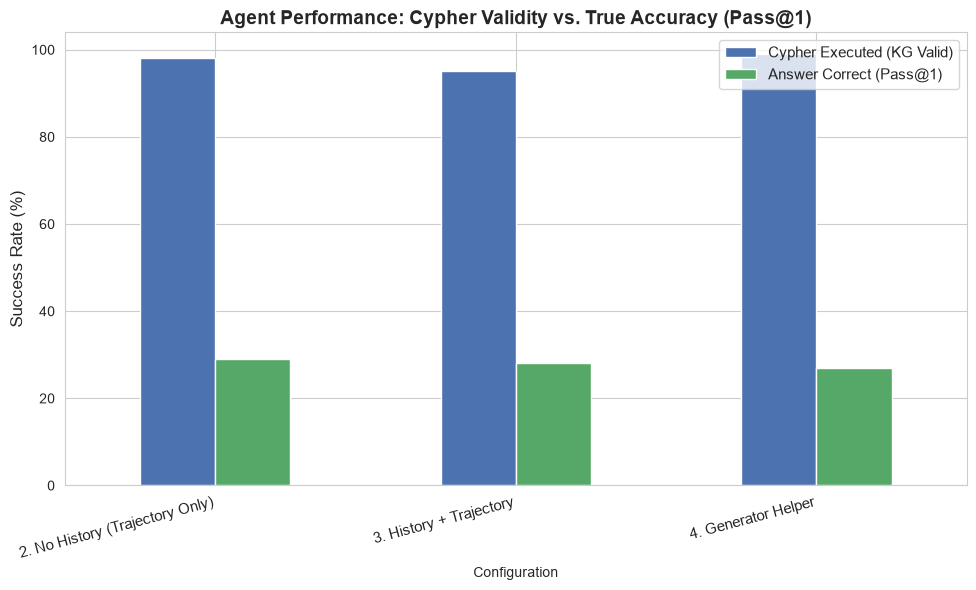

C:\Users\olgag\AppData\Local\Temp\ipykernel_3192\4270593007.py:72: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=combined_df, x='Configuration', y='total_iterations', ci=None, palette='Blues_d')
C:\Users\olgag\AppData\Local\Temp\ipykernel_3192\4270593007.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=combined_df, x='Configuration', y='total_iterations', ci=None, palette='Blues_d')


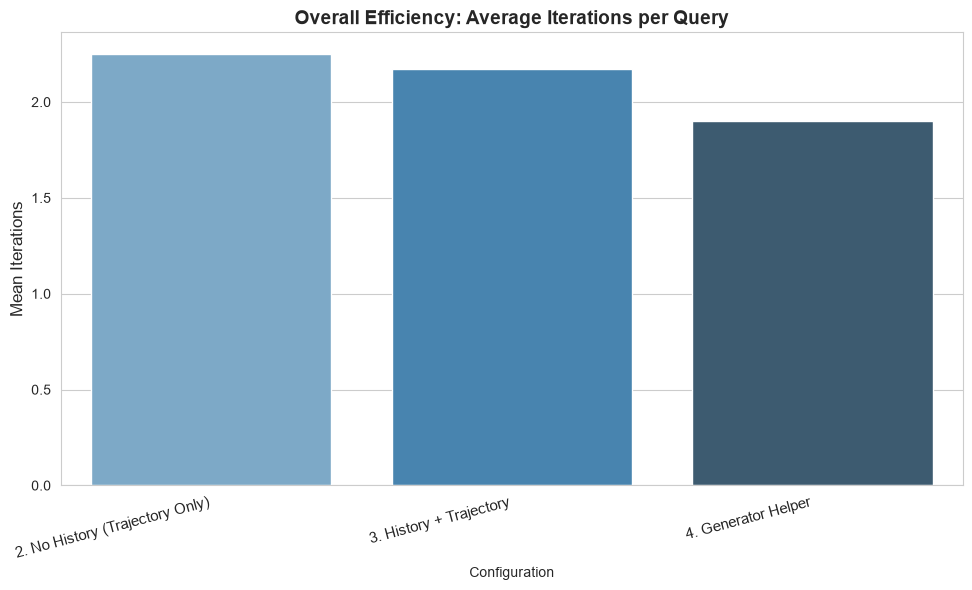

C:\Users\olgag\AppData\Local\Temp\ipykernel_3192\4270593007.py:86: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=correct_only_df, x='Configuration', y='total_iterations', ci=None, palette='Greens_d')
C:\Users\olgag\AppData\Local\Temp\ipykernel_3192\4270593007.py:86: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=correct_only_df, x='Configuration', y='total_iterations', ci=None, palette='Greens_d')


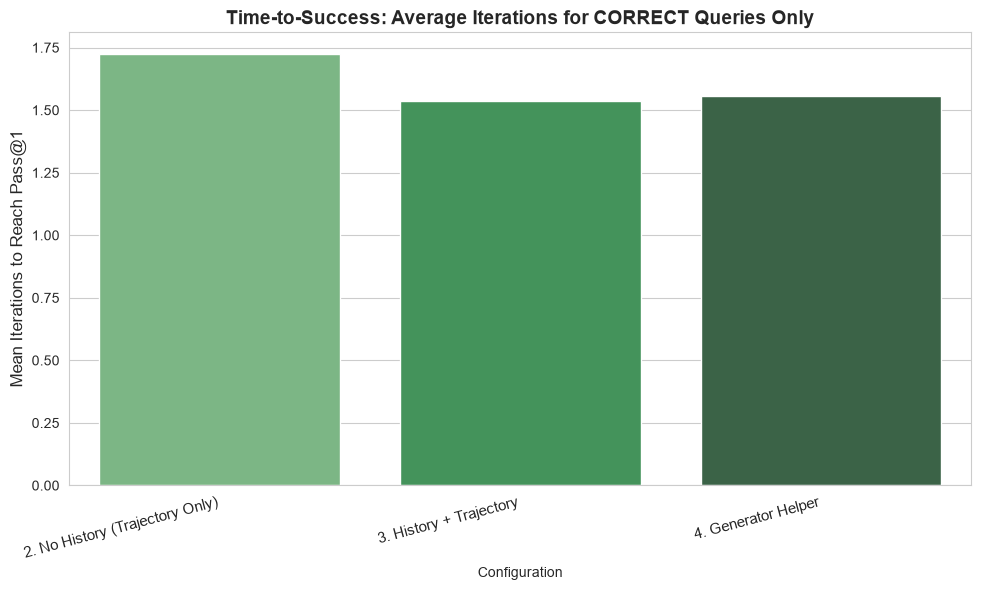

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. LOAD YOUR 4 EXPERIMENT FILES
# ==========================================
# Update these paths to match your actual Output Evaluation folders
#"1. Baseline (No Memory)": "Outputs_Evaluation/.../llama3_1_8b_baseline.xlsx",
# "2. No History (Trajectory Only)": "Outputs_Evaluation/.../llama3_1_8b_no_history_only_trajectory_run_1.xlsx",
# "3. History + Trajectory": "Outputs_Evaluation/.../llama3_1_8b_history_and_trajectory_run_1.xlsx",
# "4. Generator Helper": "Outputs_Evaluation/.../llama3_1_8b_generator_recall_run_1.xlsx"
files = {
    "2. No History (Trajectory Only)": "Testing/llama3_1_8b_no_history_only_trajectory_run_1.xlsx",
    "3. History + Trajectory": "Testing/llama3_1_8b_history_and_trajectory_run_1.xlsx",
    "4. Generator Helper": "Testing/llama3_1_8b_generator_recall_run_1.xlsx"
}

all_dfs = []
for case_name, file_path in files.items():
    try:
        df = pd.read_excel(file_path)
        df['Configuration'] = case_name
        
        # Calculate iterations using the exact logic from your Metrics block
        def extract_iterations(history_value):
            # If it's completely empty, it passed on the very first try (1 iteration)
            if pd.isna(history_value) or str(history_value).strip() in ["", "None", "[]"]:
                return 1
            try:
                history_list = eval(str(history_value))
                
                # The length of the outer list is the exact number of iterations it took!
                # (e.g., 4 failed lists + 1 empty success list = 5 iterations)
                return len(history_list)
                
            except:
                return 1
                
        df['total_iterations'] = df['cypher_errors_history'].apply(extract_iterations)
        
        # Ensure booleans are formatted correctly for plotting
        df['Pass@1 Output'] = df['Pass@1 Output'].fillna(False).astype(bool)
        df['is_KG_Valid_correct'] = df['is_KG_Valid_correct'].fillna(False).astype(bool)
        
        all_dfs.append(df)
    except Exception as e:
        print(f"⚠️ Could not load {case_name}. Make sure the file exists!")

if len(all_dfs) == 3: # Wait until all 4 are loaded to plot
    combined_df = pd.concat(all_dfs, ignore_index=True)
    sns.set_style("whitegrid")
    
    # ==========================================
    # CHART 1: Cypher Validity vs Output Validity
    # ==========================================
    validity_stats = combined_df.groupby('Configuration')[['is_KG_Valid_correct', 'Pass@1 Output']].mean() * 100
    
    plt.figure(figsize=(10, 6))
    validity_stats.plot(kind='bar', color=['#4C72B0', '#55A868'], ax=plt.gca())
    plt.title('Agent Performance: Cypher Validity vs. True Accuracy (Pass@1)', fontsize=14, fontweight='bold')
    plt.ylabel('Success Rate (%)', fontsize=12)
    plt.xticks(rotation=15, ha='right', fontsize=11)
    plt.legend(['Cypher Executed (KG Valid)', 'Answer Correct (Pass@1)'], fontsize=11)
    plt.tight_layout()
    plt.show()

    # ==========================================
    # CHART 2: Iterations (All Queries)
    # ==========================================
    plt.figure(figsize=(10, 6))
    sns.barplot(data=combined_df, x='Configuration', y='total_iterations', ci=None, palette='Blues_d')
    plt.title('Overall Efficiency: Average Iterations per Query', fontsize=14, fontweight='bold')
    plt.ylabel('Mean Iterations', fontsize=12)
    plt.xticks(rotation=15, ha='right', fontsize=11)
    plt.tight_layout()
    plt.show()

    # ==========================================
    # CHART 3: Advanced Iterations (Correct Only)
    # ==========================================
    # Filter to only look at rows where the agent ultimately got the right answer
    correct_only_df = combined_df[combined_df['Pass@1 Output'] == True]
    
    plt.figure(figsize=(10, 6))
    sns.barplot(data=correct_only_df, x='Configuration', y='total_iterations', ci=None, palette='Greens_d')
    plt.title('Time-to-Success: Average Iterations for CORRECT Queries Only', fontsize=14, fontweight='bold')
    plt.ylabel('Mean Iterations to Reach Pass@1', fontsize=12)
    plt.xticks(rotation=15, ha='right', fontsize=11)
    plt.tight_layout()
    plt.show()

In [12]:
import pandas as pd
import numpy as np

# ==========================================
# 1. LOAD YOUR 4 EXPERIMENT FILES
# ==========================================
# Update these paths to match your actual Output Evaluation folders
#"1. Baseline (No Memory)": "Outputs_Evaluation/.../llama3_1_8b_baseline.xlsx",
# "2. No History (Trajectory Only)": "Outputs_Evaluation/.../llama3_1_8b_no_history_only_trajectory_run_1.xlsx",
# "3. History + Trajectory": "Outputs_Evaluation/.../llama3_1_8b_history_and_trajectory_run_1.xlsx",
# "4. Generator Helper": "Outputs_Evaluation/.../llama3_1_8b_generator_recall_run_1.xlsx"
files = {
    "2. No History (Trajectory Only)": "Testing/llama3_1_8b_no_history_only_trajectory_run_1.xlsx",
    "3. History + Trajectory": "Testing/llama3_1_8b_history_and_trajectory_run_1.xlsx",
    "4. Generator Helper": "Testing/llama3_1_8b_generator_recall_run_1.xlsx"
}

# These are the exact columns from your evaluation script
metrics_mapping = {
    'is_KG_Valid_correct': 'Cypher Validity (%)',
    'Pass@1 Output': 'Pass@1 Output (%)',
    'Jaccard Output': 'Positive Jaccard (%)',
    'Jaro Similarity': 'Jaro Similarity',
    'Rouge-L F1-score': 'Rouge-L F1'
}

table_rows = []

for case_name, file_path in files.items():
    try:
        df = pd.read_excel(file_path)
        
        # Safely convert boolean columns so pandas can do math on them
        df['is_KG_Valid_correct'] = df['is_KG_Valid_correct'].fillna(False).astype(bool)
        df['Pass@1 Output'] = df['Pass@1 Output'].fillna(False).astype(bool)
        df['Jaccard Output'] = df['Jaccard Output'].fillna(False).astype(bool)
        
        row_data = {'Configuration (Llama-3.1-8B)': case_name}
        
        for col, clean_name in metrics_mapping.items():
            if col in df.columns:
                # Calculate the mean and multiply by 100 to match standard academic 0-100 formatting
                val = df[col].mean() * 100
                row_data[clean_name] = round(val, 2)
            else:
                row_data[clean_name] = "N/A"
                
        table_rows.append(row_data)
        
    except Exception as e:
        print(f"⚠️ Could not load {case_name}. Make sure the file exists and the path is correct!")

# ==========================================
# 2. GENERATE AND DISPLAY THE TABLE
# ==========================================
if table_rows:
    summary_table = pd.DataFrame(table_rows)
    
    print("\n" + "="*80)
    print(" 📊 ABLATION STUDY METRIC SUMMARY TABLE")
    print("="*80)
    
    # Display the clean table in the notebook
    display(summary_table)
    
    # Optional: Save this table directly to an Excel file so you can copy-paste it into Word/LaTeX!
    summary_table.to_excel("Ablation_Study_Summary_Table.xlsx", index=False)
    print("\n✅ Table successfully saved to your folder as 'Ablation_Study_Summary_Table.xlsx'")


 📊 ABLATION STUDY METRIC SUMMARY TABLE


,Configuration (Llama-3.1-8B),Cypher Validity (%),Pass@1 Output (%),Positive Jaccard (%),Jaro Similarity,Rouge-L F1
0,2. No History (Trajectory Only),98.0,29.0,60.0,84.99,65.34
1,3. History + Trajectory,95.0,28.0,69.0,86.74,68.21
2,4. Generator Helper,99.0,27.0,73.0,86.83,66.23



✅ Table successfully saved to your folder as 'Ablation_Study_Summary_Table.xlsx'


In [2]:
import pandas as pd
import numpy as np

# ==========================================
# 1. LOAD YOUR 4 EXPERIMENT FILES
# ==========================================
#"1. Baseline (No Memory)": "Outputs_Evaluation/.../llama3_1_8b_baseline.xlsx",
# "2. No History (Trajectory Only)": "Outputs_Evaluation/.../llama3_1_8b_no_history_only_trajectory_run_1.xlsx",
# "3. History + Trajectory": "Outputs_Evaluation/.../llama3_1_8b_history_and_trajectory_run_1.xlsx",
# "4. Generator Helper": "Outputs_Evaluation/.../llama3_1_8b_generator_recall_run_1.xlsx"
files = {
    "2. No History (Trajectory Only)": "Testing/llama3_1_8b_no_history_only_trajectory_run_1.xlsx",
    "3. History + Trajectory": "Testing/llama3_1_8b_history_and_trajectory_run_1.xlsx",
    "4. Generator Helper": "Testing/llama3_1_8b_generator_recall_run_1.xlsx"
}

table_rows = []

# Function to extract iterations exactly as we did for the diagrams
def extract_iterations(history_value):
    # If it's completely empty, it passed on the very first try (1 iteration)
    if pd.isna(history_value) or str(history_value).strip() in ["", "None", "[]"]:
        return 1
    try:
        history_list = eval(str(history_value))
        
        # The length of the outer list is the exact number of iterations it took!
        # (e.g., 4 failed lists + 1 empty success list = 5 iterations)
        return len(history_list)
        
    except:
        return 1

for case_name, file_path in files.items():
    try:
        df = pd.read_excel(file_path)
        
        # Ensure boolean for filtering
        df['Pass@1 Output'] = df['Pass@1 Output'].fillna(False).astype(bool)
        
        # Calculate iterations
        df['total_iterations'] = df['cypher_errors_history'].apply(extract_iterations)
        
        # Metric 1: Overall mean iterations across all 100 queries
        overall_mean = df['total_iterations'].mean()
        
        # Metric 2: Mean iterations for CORRECT queries only (Pass@1 == True)
        correct_df = df[df['Pass@1 Output'] == True]
        correct_mean = correct_df['total_iterations'].mean() if not correct_df.empty else np.nan
        
        # Metric 3: % of queries resolved perfectly on the 1st try (1 iteration)
        first_try_pass = (df['total_iterations'] == 1).mean() * 100
        
        row_data = {
            'Configuration (Llama-3.1-8B)': case_name,
            'Overall Mean Iterations': round(overall_mean, 2),
            'Mean Iterations (Correct Outputs Only)': round(correct_mean, 2) if not np.isnan(correct_mean) else "N/A",
            'Zero-Shot Success Rate (%)': round(first_try_pass, 2)
        }
        
        table_rows.append(row_data)
        
    except Exception as e:
        print(f"⚠️ Could not load {case_name}. Make sure the file exists and the path is correct!")

# ==========================================
# 2. GENERATE AND DISPLAY THE TABLE
# ==========================================
if table_rows:
    iteration_table = pd.DataFrame(table_rows)
    
    print("\n" + "="*85)
    print(" ⏱️ ABLATION STUDY: AGENT EFFICIENCY & ITERATION SUMMARY")
    print("="*85)
    
    # Display the clean table in the notebook
    display(iteration_table)
    
    # Save this table directly to an Excel file so you can copy-paste it into LaTeX/Word
    iteration_table.to_excel("Ablation_Study_Iteration_Table.xlsx", index=False)
    print("\n✅ Iteration table successfully saved to your folder as 'Ablation_Study_Iteration_Table.xlsx'")


 ⏱️ ABLATION STUDY: AGENT EFFICIENCY & ITERATION SUMMARY


,Configuration (Llama-3.1-8B),Overall Mean Iterations,Mean Iterations (Correct Outputs Only),Zero-Shot Success Rate (%)
0,2. No History (Trajectory Only),2.25,1.72,63.0
1,3. History + Trajectory,2.17,1.54,65.0
2,4. Generator Helper,1.90,1.56,58.0



✅ Iteration table successfully saved to your folder as 'Ablation_Study_Iteration_Table.xlsx'


In [1]:
import os
import pandas as pd
from tqdm import tqdm
import torch
from neo4j import GraphDatabase

# With limit for testing
def evaluate_model(model_name, model, dataset, limit=None, target_db='movies'):

    # Get datasets 
    if dataset == 'sustain':
        df = pd.read_excel('../data/text2cypher-sustaingraph/sustaintest.xlsx', sheet_name='Queries')
        subfolder = 'SustainDataset'
    elif dataset == 'benchmark2025':
        df = pd.read_excel('../data/text2cypher-2025v1/test.xlsx')
        df = df[df['url'].notna()].reset_index(drop=True)
        subfolder = 'BenchmarkDataset2025'
        # Filter for specific DB and slice target count
        df = df[df['database_name'] == target_db].reset_index(drop=True)
        df = df.head(limit).reset_index(drop=True)
    elif dataset == 'benchmark2024':
        df = pd.read_excel('../data/text2cypher-2024v1/test.xlsx')
        df = df[df['url'].notna()].reset_index(drop=True)
        subfolder = 'BenchmarkDataset2024'
        # Filter for specific DB and slice target count
        df = df[df['database_name'] == target_db].reset_index(drop=True)
        df = df.head(limit).reset_index(drop=True)
    
    # # Loading dataset
    # if dataset == 'sustain':
    #     df = pd.read_excel('../data/text2cypher-sustaingraph/sustaintest.xlsx', sheet_name='Queries')
    #     subfolder = 'SustainDataset'
    # elif dataset == 'benchmark2025':
    #     df = pd.read_excel('../data/text2cypher-2025v1/test.xlsx')
    #     df = df[df['url'].notna()].reset_index(drop=True)
    #     subfolder = 'BenchmarkDataset2025'
    # elif dataset == 'benchmark2024':
    #     df = pd.read_excel('../data/text2cypher-2024v1/test.xlsx')
    #     df = df[df['url'].notna()].reset_index(drop=True)
    #     subfolder = 'BenchmarkDataset2024'
    # else:
    #     raise ValueError("Invalid dataset name!")
        
    if limit is not None:
        df = df.head(limit)
        print(f"\n TEST: Only first {limit} questions!\n")

    # For outputs
    output_dir = f"Outputs_Evaluation/{subfolder}/{model_name}/"
    os.makedirs(output_dir, exist_ok=True)

    results_path_pkl = os.path.join(output_dir, f"{model_name}.pkl")
    results_path_xlsx = os.path.join(output_dir, f"{model_name}.xlsx")
   
    # Resume ignoring the completed questions 
    if os.path.exists(results_path_xlsx):
        print(f"Found existing progress at {results_path_xlsx}. Resuming...")
        df_results = pd.read_excel(results_path_xlsx)
    else:
        df_results = df.copy() 
        new_cols = ['generated_cypher', 'answer', 'path', 'output', 'cypher_errors_history', 
                    'cypher_errors', 'is_KG_Valid_correct', 'total_tokens', 
                    'completion_tokens', 'prompt_tokens', 'is_KG_Valid_correct_with_full_schema']
        for col in new_cols:
            df_results[col] = None

    # LangGraph config
    config = {
        'configurable': {
            'model': model, 
            'model_name': model_name, 
            'attempts_w_filtered': 3, 
            'total_attempts': 5
        },
        'recursion_limit': 50
    }
    
    print(f'Starting evaluation for {model_name} on {dataset} ...')

    # Main Loop
    for i, row in tqdm(df_results.iterrows(), total=df_results.shape[0]):
        if pd.isna(row['generated_cypher']):
            question = row['Question'] if dataset == 'sustain' else row['question']
            
            # Getting credentials for all neo4j dbs
            required_cols = {'database_name', 'url', 'username', 'password'}
            if required_cols.issubset(df_results.columns):
                database_url = row['url']
                database_name = row['database_name']
                database_user = row['username']
                database_password = row['password']
            else:
                database_url = os.getenv('NEO4J_URI')
                database_name = os.getenv('GRAPH_DATABASE_NAME', 'neo4j')
                database_user = os.getenv('NEO4J_USERNAME')
                database_password = os.getenv('NEO4J_PASSWORD')

            inputs = {
                'question': question,
                'database_url': database_url,
                'database_name': database_name,
                'database_user': database_user,
                'database_password': database_password
            }

            print("=" * 80)
            print(f"Row: {i}")
            print(f"URL      : {repr(database_url)}")
            print(f"Database : {repr(database_name)}")
            print(f"User     : {repr(database_user)}")
            print(f"Password : {repr(database_password)}")
            print(inputs)
            print("=" * 80)
            
            try:
                result = app.invoke(inputs, config=config)
                
                df_results.at[i, 'generated_cypher'] = result.get('cypher_statement', '')
                df_results.at[i, 'output'] = str(result.get('database_records', ''))
                df_results.at[i, 'path'] = str(result.get('path', [])) 
                df_results.at[i, 'cypher_errors'] = str(result.get('cypher_errors', []))
                df_results.at[i, 'cypher_errors_history'] = str(result.get('cypher_errors_history', []))
                df_results.at[i, 'is_KG_Valid_correct'] = result.get('is_KG_Valid_correct', False)
                df_results.at[i, 'answer'] = result.get('answer', '')
                
                path_list = result.get('path', [])
                valid_correct = result.get('is_KG_Valid_correct', False)
                df_results.at[i, 'is_KG_Valid_correct_with_full_schema'] = ('schema_retriever' in path_list) and valid_correct
                
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
                    
                df_results.to_pickle(results_path_pkl)
                df_results.to_excel(results_path_xlsx, index=False)
                
            except Exception as e:
                print(f"Error at index {i}: {e}")
                df_results.at[i, 'generated_cypher'] = "ERROR"
                df_results.at[i, 'answer'] = str(e)
                df_results.to_excel(results_path_xlsx, index=False)
                
    print(f"\nEvaluation Complete! Results saved at: {results_path_xlsx}")
    return df_results

KeyboardInterrupt: 

In [ ]:
# ONLY n questions my laptop can't take much!
test_results_df = evaluate_model(
    model_name="agent_test", 
    model=model,                      
    dataset="benchmark2024",           
    limit=100,
    target_db='movies'                       
)

# Printing results to check 
display(test_results_df[['question', 'generated_cypher', 'is_KG_Valid_correct']])


 TEST: Only first 100 questions!

Found existing progress at Outputs_Evaluation/BenchmarkDataset2024/agent_test/agent_test.xlsx. Resuming...
Starting evaluation for agent_test on benchmark2024 ...


  0%|          | 0/100 [00:00<?, ?it/s]

Schema filtering Agent: START
Cypher Generator: START
CyVer Evaluator: START
CyVer Evaluation of MATCH (u:User)-[:VIP]->(s:Stream)<-[:VIP]-(s2:Stream)<-[:VIP]-(s3:Stream) WHERE s <> s2 AND s <> s3 AND (u)-[:MODERATOR]->(:Stream) RETURN COUNT(DISTINCT u):
Cypher Executor: START
Executing Cypher: MATCH (u:User)-[:VIP]->(s:Stream)<-[:VIP]-(s2:Stream)<-[:VIP]-(s3:Stream) WHERE s <> s2 AND s <> s3 AND (u)-[:MODERATOR]->(:Stream) RETURN COUNT(DISTINCT u)
Records found: 1
Cypher Executor: END
Output Generator: START
Agent Answer: I found the following in the database: COUNT(DISTINCT u): 238
Output Generator: END
Error at index 3: Invalid value 'True' for dtype 'float64'


  4%|▍         | 4/100 [00:18<07:19,  4.58s/it]

Schema filtering Agent: START
Cypher Generator: START
CyVer Evaluator: START
CyVer Evaluation of MATCH (t:Tweet) RETURN t.id ORDER BY t.created_at ASC LIMIT 1:
Cypher Executor: START
Executing Cypher: MATCH (t:Tweet) RETURN t.id ORDER BY t.created_at ASC LIMIT 1
Records found: 1
Cypher Executor: END
Output Generator: START
Agent Answer: I found the following in the database: t.id: 1335451913203163138
Output Generator: END
Error at index 4: Invalid value 'True' for dtype 'float64'


  5%|▌         | 5/100 [00:28<09:31,  6.02s/it]

Schema filtering Agent: START
Error at index 5: Existing exports of data: object cannot be re-sized


  6%|▌         | 6/100 [00:31<08:21,  5.33s/it]

Schema filtering Agent: START
Cypher Generator: START
CyVer Evaluator: START
CyVer Evaluation of MATCH (me:User {name: 'Me'})-[:AMPLIFIES]->(u:User) RETURN u:
Cypher Executor: START


For Gemma 9b add : 


if database_name == 'offshoreleaks':

print(f'Skipping row {i}, to avoid memory error in {database_name}')

continue

In [ ]:
def evaluate_model (model_name, model, dataset):
    ''' 
    Evaluate the selected model on the given dataset, by invoking the graph workflow.
    Save the dataframe with the questions and the generated cypher queries to the Outputs_Evaluation folder.
    Return the dataframe
    '''
    # torch.cuda.empty_cache()#clear gpu cache
    # Get datasets 
    if dataset =='sustain':
        df = pd.read_excel('../data/text2cypher-sustaingraph/sustaintest.xlsx',sheet_name='Queries')
        subfolder = 'SustainDataset'
    elif dataset == 'benchmark2025':
        df = pd.read_excel('../data/text2cypher-2025v1/test.xlsx')
        #update df only with rows with a database access
        df = df[df['url'].notna()].reset_index(drop=True)
        subfolder = 'BenchmarkDataset2025'
    elif dataset == 'benchmark2024':
        df = pd.read_excel('../data/text2cypher-2024v1/test.xlsx')
        #update df only with rows with a database access
        df = df[df['url'].notna()].reset_index(drop=True)
        subfolder = 'BenchmarkDataset2024'
    
    output_dir = f"Outputs_Evaluation/{subfolder}/{model_name}/"
    # Create the directory if it doesn't exist
    os.makedirs(output_dir, exist_ok=True)

    results_path_pkl = os.path.join(output_dir, f"{model_name}.pkl")
    results_path_xlsx = os.path.join(output_dir, f"{model_name}.xlsx")
   
    # Check if results file already exists
    if os.path.exists(results_path_xlsx):
        df_results = pd.read_excel(results_path_xlsx)
    else:# Run model on dataset
        df_results = df.copy() # Copy of the df with questions and expected answers, to add the answers of the llm 
        # Now define additional columns in df_results to store LLM results:
        df_results['generated_cypher'] = None 
        df_results['answer'] = None
        df_results['path'] = None           # Use None so we can store a list
        df_results['output'] = None           # Use None so we can store a list
        df_results['cypher_errors_history'] = None           # Use None so we can store a list
        df_results['cypher_errors'] = None           # Use None so we can store a list
        df_results['is_KG_Valid_correct'] = None           # Use None so we can store a list
        df_results['total_tokens'] = None           # Use None so we can store a list
        df_results['completion_tokens'] = None           # Use None so we can store a list
        df_results['prompt_tokens'] = None           # Use None so we can store a list

    config = {'configurable': {'model': model, 'model_name':model_name, 'attempts_w_filtered':5, 'total_attempts':10},'recursion_limit':50}
    
    print(f'Starting evaluation for {model_name} on {dataset} ...')
    # Iterate over each row and compute only if not already done
    for i, row in tqdm(df_results.iterrows(), total=df_results.shape[0]):
        if pd.isna(row['generated_cypher']):
            question = row['Question'] if dataset == 'sustain' else row['question']
            print(i,question)
            
            # Get credentials
            required_cols = {'database_name', 'url', 'username', 'password'}
            if required_cols.issubset(df_results.columns):
                database_url = row['url']
                database_name = row['database_name']
                database_user = row['username']
                database_password = row['password']
            else:
                #its the sustain dataset
                database_url = os.getenv('database_url')
                database_name = os.getenv('database_name')
                database_user = os.getenv('database_user')
                database_password = os.getenv('database_password')
                # activate it for gemma 9b
                # if database_name == 'offshoreleaks':
                #     print(f'Skipping row {i}, to avoid memory error in {database_name}')
                #     continue
                # else:# Configuration 
                inputs = {
                    'question':question,
                    'database_url': database_url,
                    'database_name':database_name,
                    'database_user':database_user,
                    'database_password':database_password
                }
                # torch.cuda.empty_cache() #clear gpu cache
            
                # Run the graph and save outputs
                result =app.invoke(inputs, config =config) #,debug=False
                df_results.at[i, 'generated_cypher'] = result['cypher_statement']
                df_results.at[i, 'output'] = str(result['database_records'])
                df_results.at[i, 'path'] = result['path']
                df_results.at[i, 'cypher_errors'] = result['cypher_errors']
                df_results.at[i, 'cypher_errors_history'] = result['cypher_errors_history']
                df_results.at[i, 'is_KG_Valid_correct'] = result['is_KG_Valid_correct']
                df_results.at[i, 'answer'] = result['answer']
                df_results.at[i, 'total_tokens'] = result['total_tokens']
                df_results.at[i, 'completion_tokens'] = result['completion_tokens']
                df_results.at[i, 'prompt_tokens'] = result['prompt_tokens']
                if ('schema_retriever' in result['path']) and result['is_KG_Valid_correct']:
                    df_results.at[i, 'is_KG_Valid_correct_with_full_schema'] = True
                else:
                    df_results.at[i, 'is_KG_Valid_correct_with_full_schema'] = False
                torch.cuda.empty_cache()#clear gpu cache
                
                # Save results
                df_results.to_pickle(results_path_pkl)
                df_results.to_excel(results_path_xlsx, index=False)# Set index=False to exclude the index column in Excel
        else:
            print(f"Skipping row {i}, already computed.")
            
    return df_results

In [ ]:
model_name = 'llama3_2_3b'
df_results = evaluate_model (model_name, models[model_name](), 'benchmark2025')

# Evaluate with computational metrics

In [2]:
def evaluate_model_usage (model_name, model, dataset):
    ''' 
    Evaluate the selected model on the given dataset, by invoking the graph workflow.
    Save the dataframe with the questions and the generated cypher queries to the Outputs_Evaluation folder.
    Return the dataframe
    '''
    # torch.cuda.empty_cache()#clear gpu cache
    # Get datasets 
    if dataset =='sustain':
        df = pd.read_excel('../data/text2cypher-sustaingraph/sustaintest.xlsx',sheet_name='Queries')
        subfolder = 'SustainDataset'
    elif dataset == 'benchmark2025':
        df = pd.read_excel('../data/text2cypher-2025v1/test.xlsx')
        #update df only with rows with a database access
        df = df[df['url'].notna()].reset_index(drop=True)
        subfolder = 'BenchmarkDataset2025'
    elif dataset == 'benchmark2024':
        df = pd.read_excel('../data/text2cypher-2024v1/test.xlsx')
        #update df only with rows with a database access
        df = df[df['url'].notna()].reset_index(drop=True)
        subfolder = 'BenchmarkDataset2024'
    
    output_dir = f"Outputs_Evaluation/{subfolder}/{model_name}/"
    # Create the directory if it doesn't exist
    os.makedirs(output_dir, exist_ok=True)

    results_path_pkl = os.path.join(output_dir, f"{model_name}_usage1.pkl")
    results_path_xlsx = os.path.join(output_dir, f"{model_name}_usage1.xlsx")
   
    # Check if results file already exists
    if os.path.exists(results_path_xlsx):
        df_results = pd.read_excel(results_path_xlsx)
    else:# Run model on dataset
        df_results = df.copy() # Copy of the df with questions and expected answers, to add the answers of the llm 
        # Now define additional columns in df_results to store LLM results:
        df_results['generated_cypher'] = None 
        df_results['answer'] = None
        df_results['path'] = None           # Use None so we can store a list
        df_results['output'] = None           # Use None so we can store a list
        df_results['cypher_errors_history'] = None           # Use None so we can store a list
        df_results['cypher_errors'] = None           # Use None so we can store a list
        df_results['is_KG_Valid_correct'] = None           # Use None so we can store a list
        # timing columns
        df_results['eval_time_s'] = None              # <-- total wall-clock time per query
        # tokens columns
        df_results['total_tokens'] = None           # Use None so we can store a list
        df_results['completion_tokens'] = None           # Use None so we can store a list
        df_results['prompt_tokens'] = None           # Use None so we can store a list
    config = {'configurable': {'model': model, 'model_name':model_name, 'attempts_w_filtered':5, 'total_attempts':10},'recursion_limit':50}
    
    print(f'Starting evaluation for {model_name} on {dataset} ...')
    # Iterate over each row and compute only if not already done
    for i, row in tqdm(df_results.iterrows(), total=df_results.shape[0]):
        if pd.isna(row['generated_cypher']):
            question = row['Question'] if dataset == 'sustain' else row['question']
            print(i,question)
            
            # Get credentials
            required_cols = {'database_name', 'url', 'username', 'password'}
            if required_cols.issubset(df_results.columns):
                database_url = row['url']
                database_name = row['database_name']
                database_user = row['username']
                database_password = row['password']
            else:
                #its the sustain dataset
                database_url = os.getenv('database_url')
                database_name = os.getenv('database_name')
                database_user = os.getenv('database_user')
                database_password = os.getenv('database_password')
                # activate it for gemma 9b
                # if database_name == 'offshoreleaks':
                #     print(f'Skipping row {i}, to avoid memory error in {database_name}')
                #     continue
                # else:# Configuration 
                inputs = {
                    'question':question,
                    'database_url': database_url,
                    'database_name':database_name,
                    'database_user':database_user,
                    'database_password':database_password
                }
                # torch.cuda.empty_cache() #clear gpu cache
            
                # Run the graph and save outputs
                start = time.perf_counter() # start wall-clock timer
                result =app.invoke(inputs, config =config) #,debug=False
                elapsed = time.perf_counter() - start # elapsed wall-clock time
                df_results.at[i, 'eval_time_s'] = round(elapsed, 4)
                df_results.at[i, 'generated_cypher'] = result['cypher_statement']
                df_results.at[i, 'output'] = str(result['database_records'])
                df_results.at[i, 'path'] = result['path']
                df_results.at[i, 'cypher_errors'] = result['cypher_errors']
                df_results.at[i, 'cypher_errors_history'] = result['cypher_errors_history']
                df_results.at[i, 'is_KG_Valid_correct'] = result['is_KG_Valid_correct']
                df_results.at[i, 'answer'] = result['answer']
                df_results.at[i, 'total_tokens'] = result['total_tokens']
                df_results.at[i, 'completion_tokens'] = result['completion_tokens']
                df_results.at[i, 'prompt_tokens'] = result['prompt_tokens']
                if ('schema_retriever' in result['path']) and result['is_KG_Valid_correct']:
                    df_results.at[i, 'is_KG_Valid_correct_with_full_schema'] = True
                else:
                    df_results.at[i, 'is_KG_Valid_correct_with_full_schema'] = False
                torch.cuda.empty_cache()#clear gpu cache
                

                # Save results
                df_results.to_pickle(results_path_pkl)
                df_results.to_excel(results_path_xlsx, index=False)# Set index=False to exclude the index column in Excel
        else:
            print(f"Skipping row {i}, already computed.")
            
    return df_results

In [ ]:
model_name = 'gpt_4o' # 'qwen2_5_Coder_32b' #'llama3_2_3b'
df_results = evaluate_model_usage (model_name, models[model_name](), 'sustain') #benchmark2025

Llama 3 - GPU usage:

92.6 %

90.17 %\

74.4 % 

90

85.03

92.2

75.2

93.8

92.48

90.33

91.6

64

In [ ]:
#In the Sustain dataset, Llama 3 2 3b GPU usage:#NVIDIA L4 24GB
llama3_gpu_extended = [92.6,90.17,74.4 ,90,85.03,92.2,75.2,93.8,92.48,90.33,91.6,64]
mean_usage = sum(llama3_gpu_extended)/len(llama3_gpu_extended)
print(f'Mean GPU usage for Llama 3 2 3b extended: {mean_usage} %')
median_usage = sorted(llama3_gpu_extended)[len(llama3_gpu_extended)//2]
print(f'Median GPU usage for Llama 3 2 3b extended: {median_usage} %')

Mean GPU usage for Llama 3 2 3b extended: 85.98416666666667 %
Median GPU usage for Llama 3 2 3b extended: 90.33 %


In [ ]:
# NVIDIA L4 96GB
qwen_32_coder_gpu_extended = [98.25,
100,97.25,100,98,100,97.5,97.5,97.75,100,100,100,98,100,98,100,98,100,100,96.75,97.5,100,100,97.75,99,100,100,100,97.75,98.5,98,100,96.75,96.5]
mean_usage = sum(qwen_32_coder_gpu_extended)/len(qwen_32_coder_gpu_extended)
print(f'Mean GPU usage for Qwen coder 32b extended: {mean_usage} %')
median_usage = sorted(qwen_32_coder_gpu_extended)[len(qwen_32_coder_gpu_extended)//2]
print(f'Median GPU usage for Qwen coder 32b extended: {median_usage} %')

Mean GPU usage for Qwen coder 32b extended: 98.78676470588235 %
Median GPU usage for Qwen coder 32b extended: 99 %
